**STEP 1 — Load Option Likelihood Signal Dataset**

**STEP 1.1 — Import Libraries**

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

**STEP 1.2 — Load Signal Dataset**

In [ ]:
signal_df = pd.read_csv(
    "/content/drive/MyDrive/Dissertation/option_likelihood_signals.csv"
)

print("=" * 70)
print("OPTION LIKELIHOOD SIGNAL DATASET")
print("=" * 70)

print(f"Number of observations : {len(signal_df)}")
print(f"Number of variables    : {signal_df.shape[1]}")

OPTION LIKELIHOOD SIGNAL DATASET
Number of observations : 817
Number of variables    : 6


**STEP 1.3 — Verify Dataset Structure**

In [ ]:
print("=" * 70)
print("DATASET VARIABLES")
print("=" * 70)

for i, column in enumerate(signal_df.columns, start=1):
    print(f"{i}. {column}")

DATASET VARIABLES
1. confidence
2. entropy
3. normalised_entropy
4. margin_score
5. probability_gap
6. correct


**STEP 1.4 — Missing Value Analysis**

In [ ]:
print("="*60)
print("MISSING VALUES")
print("="*60)

print(
    signal_df.isnull().sum()
)

MISSING VALUES
confidence            0
entropy               0
normalised_entropy    0
margin_score          0
probability_gap       0
correct               0
dtype: int64


**STEP 1.5 — Dataset Summary Statistics**

In [ ]:
summary_stats = signal_df.describe()

display(

    summary_stats

    .style

    .background_gradient(
        subset=["confidence"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["entropy","normalised_entropy"],
        cmap="Purples"
    )

    .background_gradient(
        subset=["margin_score","probability_gap"],
        cmap="Greens"
    )

    .format("{:.4f}")

)

,confidence,entropy,normalised_entropy,margin_score,probability_gap
count,817.0000,817.0000,817.0000,817.0000,817.0000
mean,0.3481,1.4707,0.9452,0.1095,0.1095
std,0.1258,0.3584,0.0564,0.1158,0.1158
min,0.1167,0.4504,0.5854,0.0003,0.0003
25%,0.2573,1.2974,0.9248,0.0249,0.0249
50%,0.3236,1.5060,0.9644,0.0676,0.0676
75%,0.4154,1.7241,0.9843,0.1566,0.1566
max,0.8335,2.5396,1.0000,0.6669,0.6669


**STEP 1.6 — Signal Distribution Overview**

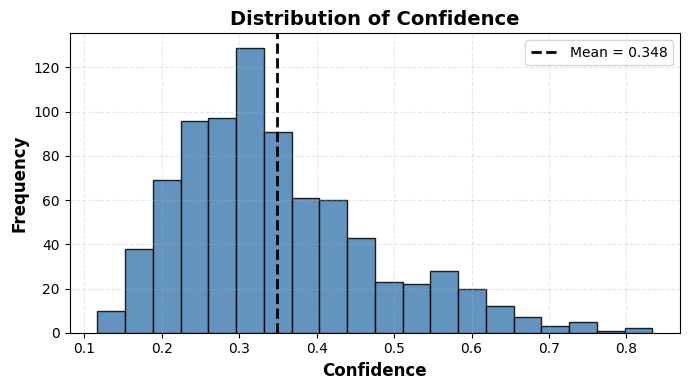

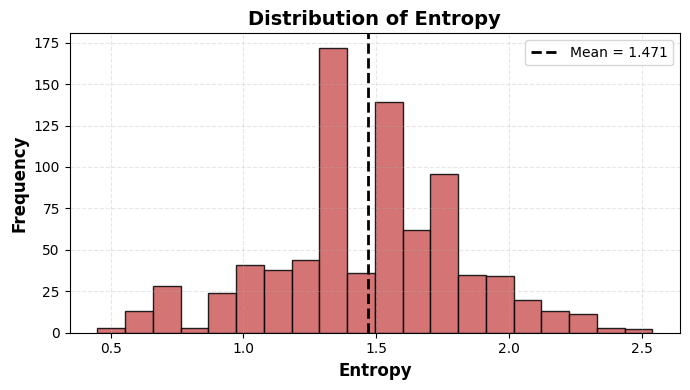

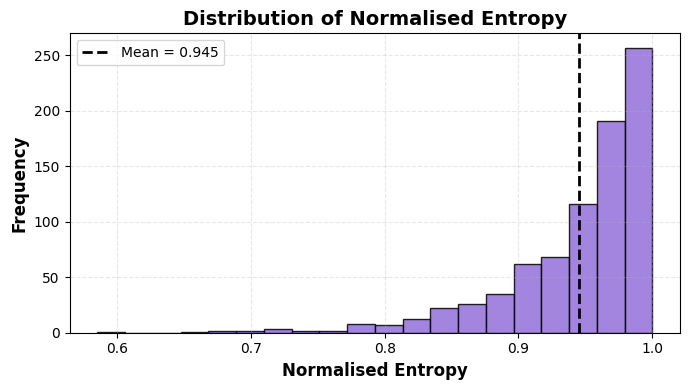

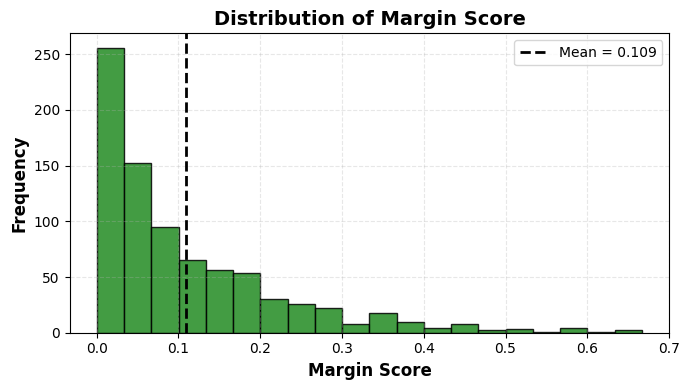

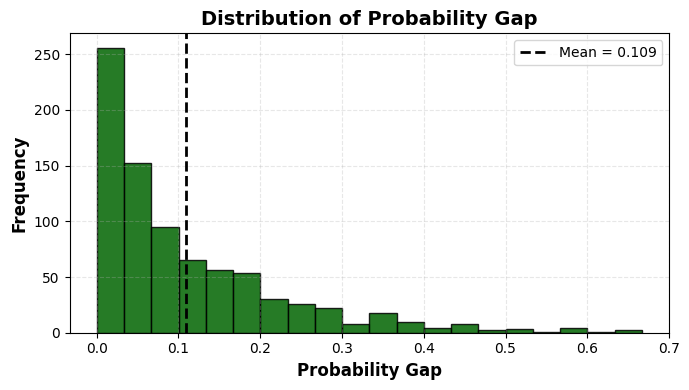

In [ ]:
plot_settings = {

    "confidence": ("Confidence", "steelblue"),

    "entropy": ("Entropy", "indianred"),

    "normalised_entropy": ("Normalised Entropy", "mediumpurple"),

    "margin_score": ("Margin Score", "forestgreen"),

    "probability_gap": ("Probability Gap", "darkgreen")

}

for column, (title, colour) in plot_settings.items():

    plt.figure(figsize=(7,4))

    plt.hist(

        signal_df[column],

        bins=20,

        color=colour,

        edgecolor="black",

        linewidth=1,

        alpha=0.85

    )

    plt.axvline(

        signal_df[column].mean(),

        color="black",

        linestyle="--",

        linewidth=2,

        label=f"Mean = {signal_df[column].mean():.3f}"

    )

    plt.xlabel(

        title,

        fontsize=12,

        fontweight="bold"

    )

    plt.ylabel(

        "Frequency",

        fontsize=12,

        fontweight="bold"

    )

    plt.title(

        f"Distribution of {title}",

        fontsize=14,

        fontweight="bold"

    )

    plt.grid(

        alpha=0.30,

        linestyle="--"

    )

    plt.legend()

    plt.tight_layout()

    plt.show()

**STEP 1.7 — Correctness Distribution**

In [ ]:
correct_counts = (

    signal_df["correct"]

    .value_counts()

    .rename_axis("Prediction")

    .reset_index(name="Count")

)

display(

    correct_counts

    .style

    .background_gradient(

        subset=["Count"],

        cmap="Blues"

    )

)

,Prediction,Count
0,True,413
1,False,404


**STEP 1.8 — Correctness Visualisation**

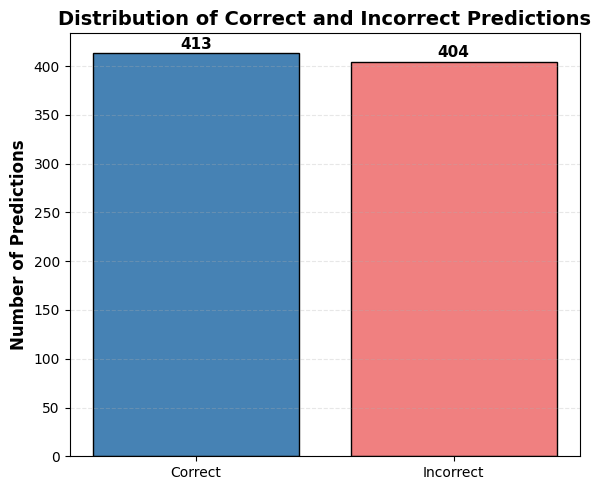

In [ ]:
plt.figure(figsize=(6,5))

bars = plt.bar(

    ["Correct","Incorrect"],

    [

        signal_df["correct"].sum(),

        (~signal_df["correct"]).sum()

    ],

    color=[

        "steelblue",

        "lightcoral"

    ],

    edgecolor="black"

)

for bar in bars:

    plt.text(

        bar.get_x()+bar.get_width()/2,

        bar.get_height()+5,

        f"{int(bar.get_height())}",

        ha="center",

        fontsize=11,

        fontweight="bold"

    )

plt.ylabel(

    "Number of Predictions",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Distribution of Correct and Incorrect Predictions",

    fontsize=14,

    fontweight="bold"

)

plt.grid(

    axis="y",

    alpha=0.30,

    linestyle="--"

)

plt.tight_layout()

plt.show()

**STEP 1.9 — Baseline Reference Metrics**

In [ ]:
baseline_accuracy = (
    signal_df["correct"]
    .astype(int)
    .mean()
)

print("="*70)
print("BASELINE MODEL PERFORMANCE")
print("="*70)

print(f"Dataset Accuracy : {baseline_accuracy:.4f}")

BASELINE MODEL PERFORMANCE
Dataset Accuracy : 0.5055


**STEP 1.10 — Save Metadata**

In [ ]:
import json

metadata = {

    "rows":
        int(len(signal_df)),

    "baseline_accuracy":
        float(baseline_accuracy)
}

with open(
    "multi_signal_metadata.json",
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

This notebook adopts a staged experimental framework to investigate whether combining complementary uncertainty signals produces more reliable confidence estimates than individual confidence measures. The analysis begins by validating the individual uncertainty signals before examining their relationships to identify complementary and redundant information. Based on these findings, multiple uncertainty signals are combined to construct fused confidence estimators, which are subsequently evaluated using discrimination, calibration and selective prediction analyses. This sequential workflow ensures methodological consistency, improves reproducibility and allows each stage of the analysis to build directly upon the empirical findings of the preceding stage.

**STEP 2 — Inter-Signal Correlation Analysis**

The objective of this step is to investigate the relationships among the uncertainty signals constructed in Notebook 3 before combining them into a unified confidence estimator. Correlation analysis identifies complementary signals that capture different aspects of predictive uncertainty, while also detecting redundant signals that provide overlapping information. Understanding these relationships is essential for constructing an interpretable and effective multi-signal confidence framework.

**STEP 2.1 — Select Signals for Analysis**

In [ ]:
signal_columns = [

    "confidence",

    "entropy",

    "normalised_entropy",

    "margin_score",

    "probability_gap"

]

signal_data = signal_df[
    signal_columns
].copy()


display(

    signal_data

    .head()

    .style

    .background_gradient(
        subset=["confidence"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["entropy","normalised_entropy"],
        cmap="Purples"
    )

    .background_gradient(
        subset=["margin_score","probability_gap"],
        cmap="Greens"
    )

    .format("{:.3f}")

)

,confidence,entropy,normalised_entropy,margin_score,probability_gap
0,0.319,1.358,0.980,0.029,0.029
1,0.410,1.486,0.923,0.229,0.229
2,0.430,1.308,0.944,0.228,0.228
3,0.385,1.334,0.962,0.146,0.146
4,0.295,1.857,0.954,0.139,0.139


**STEP 2.2 — Compute Correlation Matrix**

In [ ]:
correlation_matrix = (
    signal_data
    .corr(method="pearson")
)

display(

    correlation_matrix

    .style

    .background_gradient(
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    .format("{:.3f}")

)

,confidence,entropy,normalised_entropy,margin_score,probability_gap
confidence,1.000,-0.858,-0.686,0.833,0.833
entropy,-0.858,1.000,0.327,-0.481,-0.481
normalised_entropy,-0.686,0.327,1.000,-0.814,-0.814
margin_score,0.833,-0.481,-0.814,1.000,1.000
probability_gap,0.833,-0.481,-0.814,1.000,1.000


**STEP 2.3 — Correlation Heatmap**

<Figure size 800x600 with 0 Axes>

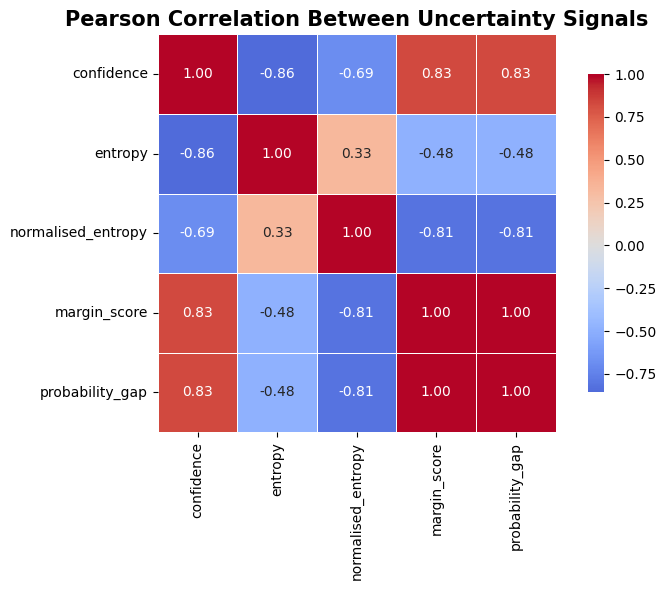

In [ ]:
plt.figure(figsize=(8,6))

plt.figure(figsize=(8,6))

sns.heatmap(

    correlation_matrix,

    annot=True,

    fmt=".2f",

    cmap="coolwarm",

    center=0,

    linewidths=0.5,

    square=True,

    cbar_kws={
        "shrink":0.8
    }

)

plt.title(

    "Pearson Correlation Between Uncertainty Signals",

    fontsize=15,

    fontweight="bold"

)

plt.tight_layout()

plt.savefig(

    "inter_signal_correlation_heatmap.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

The Pearson correlation matrix demonstrates that several uncertainty signals are strongly associated, indicating substantial overlap in the information they capture. In particular, Margin Score and Probability Gap exhibit perfect positive correlation, confirming their mathematical equivalence within this dataset. Conversely, entropy-based measures display weaker relationships with the margin-based signals, suggesting that they capture complementary characteristics of predictive uncertainty. These findings provide the empirical basis for selecting signals to include in the proposed multi-signal confidence estimator.

**STEP 2.4 — Detect Highly Correlated Signal Pairs**

In [ ]:
high_corr_pairs = []

for i in range(len(signal_columns)):

    for j in range(i + 1, len(signal_columns)):

        corr = correlation_matrix.iloc[i, j]

        if abs(corr) >= 0.80:

            high_corr_pairs.append({

                "Signal_1":
                    signal_columns[i],

                "Signal_2":
                    signal_columns[j],

                "Correlation":
                    corr
            })

high_corr_df = pd.DataFrame(
    high_corr_pairs
)

display(

    high_corr_df

    .style

    .background_gradient(

        subset=["Correlation"],

        cmap="RdYlGn"

    )

    .format({

        "Correlation":"{:.3f}"

    })

)

,Signal_1,Signal_2,Correlation
0,confidence,entropy,-0.858
1,confidence,margin_score,0.833
2,confidence,probability_gap,0.833
3,normalised_entropy,margin_score,-0.814
4,normalised_entropy,probability_gap,-0.814
5,margin_score,probability_gap,1.000


**STEP 2.5 — Signal Variance Analysis**

In [ ]:
variance_table = pd.DataFrame({

    "Signal":
        signal_columns,

    "Variance":
        [
            signal_df[col].var()
            for col in signal_columns
        ]
})

variance_table = variance_table.sort_values(
    "Variance",
    ascending=False
)

display(

    variance_table

    .style

    .background_gradient(

        subset=["Variance"],

        cmap="Greens"

    )

    .format({

        "Variance":"{:.4f}"

    })

)

,Signal,Variance
1,entropy,0.1285
0,confidence,0.0158
3,margin_score,0.0134
4,probability_gap,0.0134
2,normalised_entropy,0.0032


**STEP 2.6 — Signal Variance Visualisation**

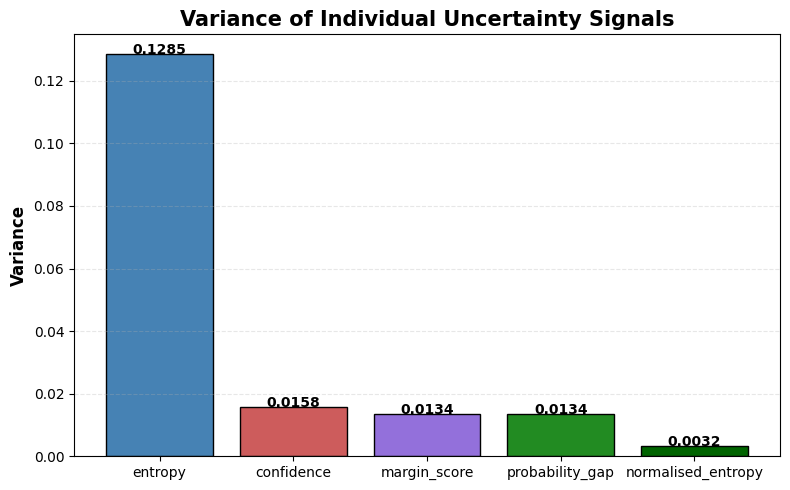

In [ ]:
plt.figure(figsize=(8,5))

colours=[

    "steelblue",

    "indianred",

    "mediumpurple",

    "forestgreen",

    "darkgreen"

]

bars=plt.bar(

    variance_table["Signal"],

    variance_table["Variance"],

    color=colours,

    edgecolor="black"

)

for bar in bars:

    plt.text(

        bar.get_x()+bar.get_width()/2,

        bar.get_height(),

        f"{bar.get_height():.4f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

)

plt.ylabel(

    "Variance",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Variance of Individual Uncertainty Signals",

    fontsize=15,

    fontweight="bold"

)

plt.grid(

    axis="y",

    alpha=0.30,

    linestyle="--"

)

plt.tight_layout()

plt.show()

**STEP 2.7 — Pairwise Scatter Analysis**

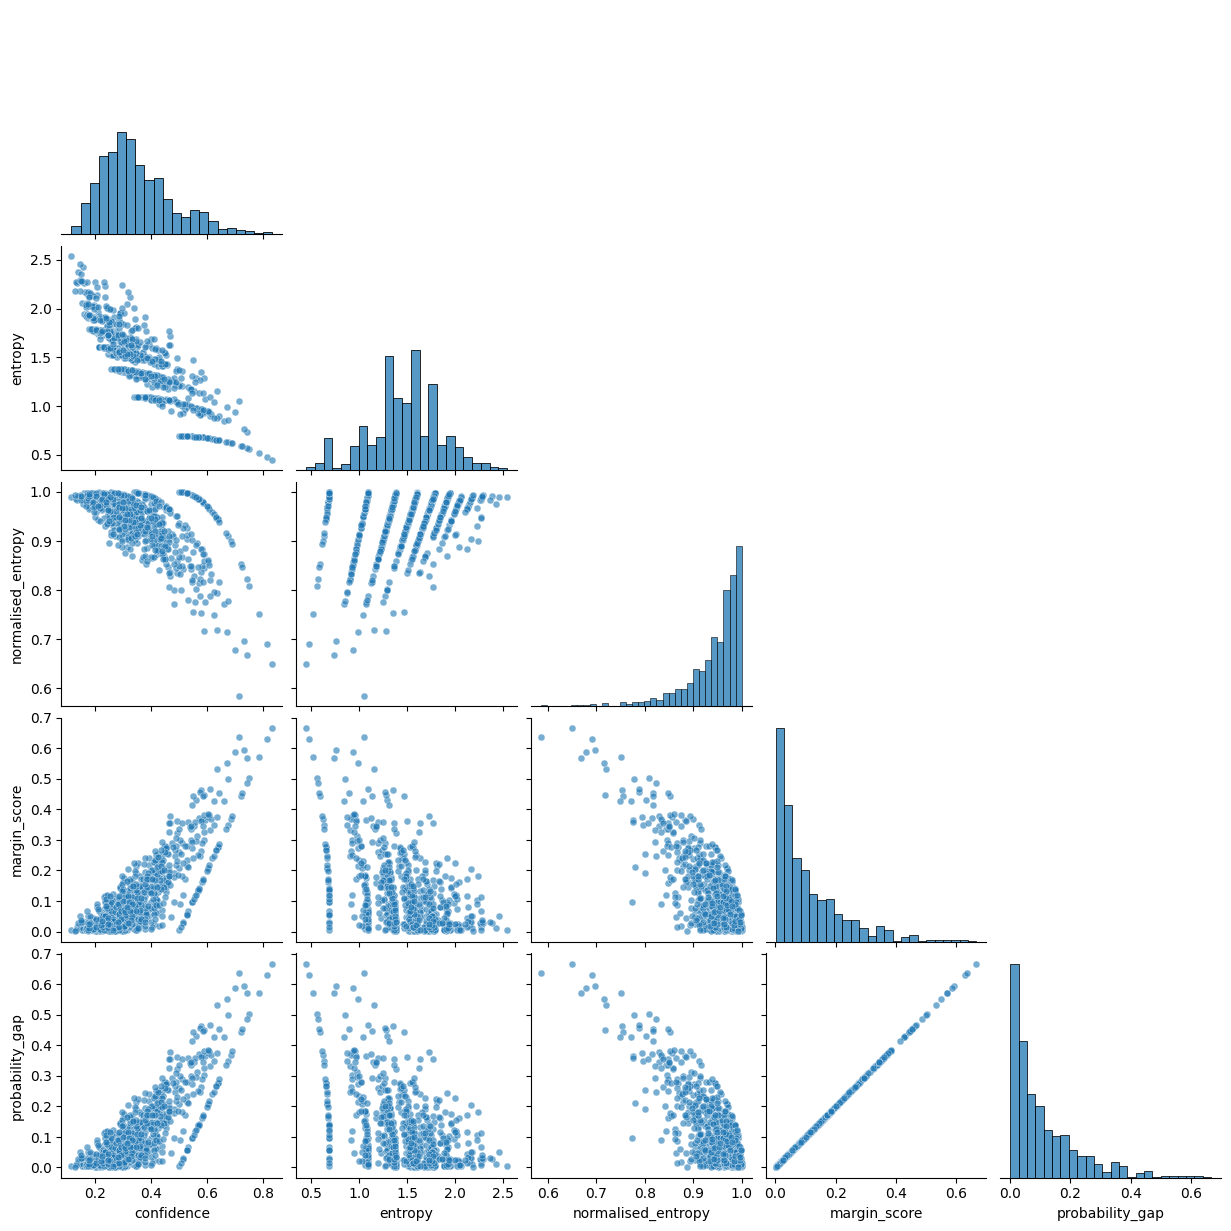

In [ ]:
sns.pairplot(

    signal_data,

    corner=True,

    diag_kind="hist",

    plot_kws={

        "alpha":0.6,

        "s":25

    }

)

The pairwise scatter plots provide a visual assessment of the relationships between uncertainty signals.

Several approximately linear relationships are visible, particularly between Margin Score and Probability Gap, supporting the correlation analysis presented earlier.

The absence of substantial non-linear structure suggests that Pearson correlation provides an appropriate measure of association for these variables.

**STEP 2.7B — Multicollinearity Assessment Using VIF**

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_df = signal_data.copy()

vif_results = pd.DataFrame({

    "Signal": vif_df.columns,

    "VIF": [
        variance_inflation_factor(vif_df.values, i)
        for i in range(vif_df.shape[1])
    ]
})

# Add interpretation
vif_results["Interpretation"] = np.where(
    np.isinf(vif_results["VIF"]),
    "Perfect multicollinearity",
    np.where(
        vif_results["VIF"] > 10,
        "High multicollinearity",
        "Acceptable"
    )
)

display(

    vif_results.style

    .background_gradient(
        subset=["VIF"],
        cmap="Reds"
    )

    .format({
        "VIF": "{:.2f}"
    })

)

/usr/local/lib/python3.12/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)
/usr/local/lib/python3.12/dist-packages/pandas/io/formats/style.py:3811: RuntimeWarning: invalid value encountered in scalar multiply
  norm = _matplotlib.colors.Normalize(smin - (rng * low), smax + (rng * high))


,Signal,VIF,Interpretation
0,confidence,109.28,High multicollinearity
1,entropy,85.22,High multicollinearity
2,normalised_entropy,247.65,High multicollinearity
3,margin_score,inf,Perfect multicollinearity
4,probability_gap,inf,Perfect multicollinearity


The infinite Variance Inflation Factor values observed for Margin Score and Probability Gap are expected because these two signals are mathematically equivalent for this dataset.

Perfect multicollinearity causes the regression used during VIF estimation to achieve an R² value of one, producing an infinite VIF.

To avoid introducing redundant information into the fusion model, Probability Gap is excluded from subsequent experiments while Margin Score is retained as the representative margin-based uncertainty signal.

**STEP 2.8 — Feature Redundancy Assessment**

In [ ]:
redundancy_summary=pd.DataFrame({

    "Statistic":[

        "Total Signals",

        "Highly Correlated Pairs"

    ],

    "Value":[

        len(signal_columns),

        len(high_corr_df)

    ]

})

display(

    redundancy_summary

    .style

    .background_gradient(

        subset=["Value"],

        cmap="Blues"

    )

)

,Statistic,Value
0,Total Signals,5
1,Highly Correlated Pairs,6


**STEP 2.8B — Redundant Signal Assessment**

In [ ]:
print("="*60)
print("REDUNDANT SIGNAL ANALYSIS")
print("="*60)

print(
    "Probability gap removed from future fusion experiments."
)

print(
    "Margin score retained."
)

REDUNDANT SIGNAL ANALYSIS
Probability gap removed from future fusion experiments.
Margin score retained.


**STEP 2.9 — Save Correlation Results**

In [ ]:
correlation_matrix.to_csv(
    "inter_signal_correlations.csv"
)

variance_table.to_csv(
    "signal_variance_analysis.csv",
    index=False
)

high_corr_df.to_csv(
    "high_correlation_pairs.csv",
    index=False
)

Collectively, the correlation, variance and multicollinearity analyses demonstrate that the uncertainty signals do not contribute equally to confidence estimation. Margin Score and Probability Gap capture identical information and therefore introducing both into the fusion framework would unnecessarily increase model complexity without improving predictive performance. In contrast, entropy-based measures provide complementary information that is only partially correlated with the margin-based signals. These findings provide a principled basis for constructing a compact yet informative multi-signal confidence estimator in the subsequent stage of the analysis.

**STEP 3 — Multi-Signal Confidence Estimator Construction**

**STEP 3.1 — Select Signals for Fusion**

In [ ]:
fusion_df = signal_df[[
    "confidence",
    "margin_score",
    "normalised_entropy"
]].copy()

display(

    fusion_df.head()

    .style

    .background_gradient(
        subset=["confidence"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["margin_score"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["normalised_entropy"],
        cmap="Purples"
    )

    .format("{:.3f}")

)

,confidence,margin_score,normalised_entropy
0,0.319,0.029,0.980
1,0.410,0.229,0.923
2,0.430,0.228,0.944
3,0.385,0.146,0.962
4,0.295,0.139,0.954


The preceding correlation and multicollinearity analyses identified Confidence, Margin Score, and Normalised Entropy as the most informative and complementary uncertainty signals. Probability Gap was excluded because it is mathematically equivalent to Margin Score and therefore contributes redundant information. These three signals were retained as the inputs to the proposed multi-signal confidence estimator.

**STEP 3.2 — Standardise Signals**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_values = scaler.fit_transform(
    fusion_df
)

scaled_df = pd.DataFrame(

    scaled_values,

    columns=fusion_df.columns
)

display(

    scaled_df.head()

    .style

    .background_gradient(
        cmap="coolwarm"
    )

    .format("{:.3f}")

)

,confidence,margin_score,normalised_entropy
0,-0.229,-0.699,0.614
1,0.494,1.034,-0.391
2,0.655,1.025,-0.024
3,0.292,0.316,0.297
4,-0.426,0.253,0.160


The selected uncertainty signals are measured on different numerical scales. Standardisation transforms each signal to zero mean and unit variance, ensuring that no individual feature dominates the fusion process purely because of its scale.

**STEP 3.3 — Reverse Entropy Direction**

In [ ]:
scaled_df["normalised_entropy"] = (
    -scaled_df["normalised_entropy"]
)

Higher confidence should consistently correspond to larger values across all fused signals. Because larger values of Normalised Entropy indicate greater uncertainty, the standardised entropy values were multiplied by −1 prior to fusion so that all signals follow the same interpretation.

**STEP 3.4 — Equal Weight Fusion**

In [ ]:
scaled_df["equal_weight_score"] = (

    scaled_df["confidence"]

    +

    scaled_df["margin_score"]

    +

    scaled_df["normalised_entropy"]

) / 3

display(

scaled_df[
    ["equal_weight_score"]
]

.head()

.style

.background_gradient(
    cmap="Greens"
)

.format("{:.3f}")

)

,equal_weight_score
0,-0.514
1,0.640
2,0.568
3,0.104
4,-0.111


An equal-weight fusion strategy was first implemented to provide a simple reference model. Each uncertainty signal contributes equally to the final confidence estimate, allowing later comparison with the data-driven weighting approach.

**STEP 3.5 — Data-Driven Correlation Weight Estimation**

In [ ]:
from scipy.stats import pearsonr

signal_weights = {}

for signal in fusion_df.columns:

    corr, _ = pearsonr(

        signal_df[signal],

        signal_df["correct"]
        .astype(int)
    )

    signal_weights[signal] = abs(corr)

total_weight = sum(
    signal_weights.values()
)

for signal in signal_weights:

    signal_weights[signal] /= total_weight

print("=" * 60)
print("NORMALISED WEIGHTS")
print("=" * 60)

print(signal_weights)

NORMALISED WEIGHTS
{'confidence': np.float64(0.3065673025163863), 'margin_score': np.float64(0.3842952383248944), 'normalised_entropy': np.float64(0.30913745915871915)}


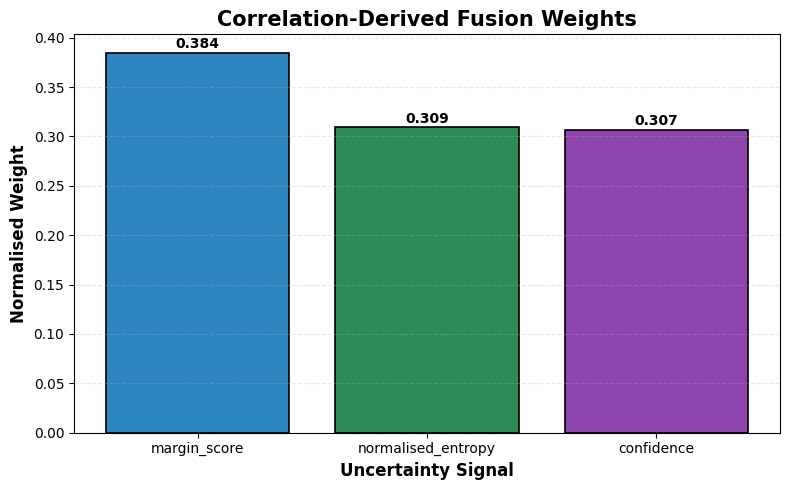

In [ ]:
import pandas as pd

weight_table = pd.DataFrame({
    "Signal":
        signal_weights.keys(),
    "Weight":
        signal_weights.values()
})

weight_table = weight_table.sort_values(
    "Weight",
    ascending=False
)

plt.figure(figsize=(8,5))

colors = [

    "#2E86C1",

    "#2E8B57",

    "#8E44AD"

]

bars = plt.bar(

    weight_table["Signal"],

    weight_table["Weight"],

    color=colors,

    edgecolor="black",

    linewidth=1.2

)

for bar in bars:

    plt.text(

        bar.get_x()+bar.get_width()/2,

        bar.get_height()+0.005,

        f"{bar.get_height():.3f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

plt.ylabel(

    "Normalised Weight",

    fontsize=12,

    fontweight="bold"

)

plt.xlabel(

    "Uncertainty Signal",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Correlation-Derived Fusion Weights",

    fontsize=15,

    fontweight="bold"

)

plt.grid(

    axis="y",

    alpha=0.30,

    linestyle="--"

)

plt.tight_layout()

plt.show()

**STEP 3.5B — Weight Interpretation**

In [ ]:
weight_table = pd.DataFrame({

    "Signal":
        signal_weights.keys(),

    "Weight":
        signal_weights.values()
})

weight_table = weight_table.sort_values(
    "Weight",
    ascending=False
)

display(

weight_table

.style

.background_gradient(

subset=["Weight"],

cmap="Greens"

)

.format({

"Weight":"{:.3f}"

})

)

,Signal,Weight
1,margin_score,0.384
2,normalised_entropy,0.309
0,confidence,0.307


Data-driven weights were estimated from the absolute Pearson correlation between each uncertainty signal and prediction correctness. The absolute values were subsequently normalised so that the weights summed to one. This weighting strategy assigns greater influence to signals exhibiting stronger empirical associations with prediction correctness while remaining simple, transparent and reproducible.

**STEP 3.6 — Weighted Signal Fusion**

In [ ]:
scaled_df["weighted_score"] = (

    signal_weights["confidence"]
    *
    scaled_df["confidence"]

    +

    signal_weights["margin_score"]
    *
    scaled_df["margin_score"]

    +

    signal_weights["normalised_entropy"]
    *
    scaled_df["normalised_entropy"]

)

**STEP 3.7 — Convert Scores to Probability Scale**

In [ ]:
from scipy.special import expit

scaled_df["equal_weight_confidence"] = expit(
    scaled_df["equal_weight_score"]
)

scaled_df["weighted_confidence"] = expit(
    scaled_df["weighted_score"]
)

**STEP 3.8 — Compare Confidence Distributions**

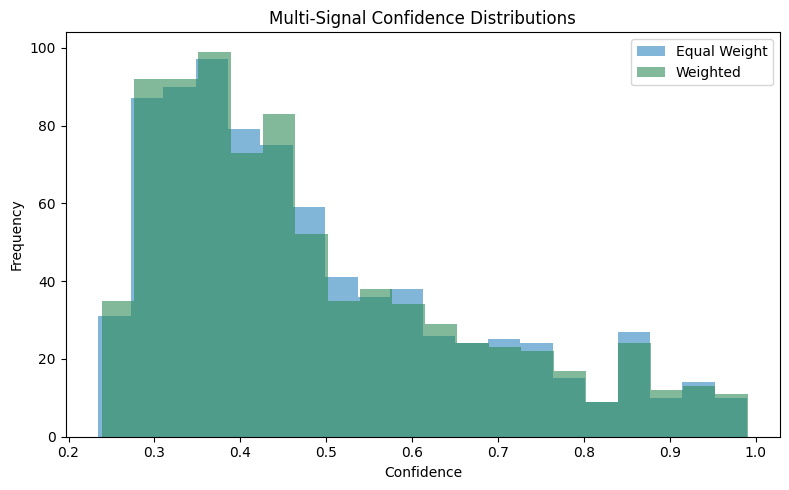

In [ ]:
import os

plt.figure(figsize=(8,5))

plt.hist(

    scaled_df["equal_weight_confidence"],

    bins=20,

    alpha=0.6,

    color="#2E86C1",

    label="Equal Weight"
)

plt.hist(

    scaled_df["weighted_confidence"],

    bins=20,

    alpha=0.6,

    color="#2E8B57",

    label="Weighted"
)

edgecolor="black"

linewidth=1


plt.legend()

plt.xlabel(
    "Confidence"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Multi-Signal Confidence Distributions"
)

os.makedirs('outputs', exist_ok=True)

plt.savefig(
    "outputs/Multi-Signal Confidence Distributions.png"
)

plt.tight_layout()

plt.show()

The weighted estimator exhibits a distribution that differs slightly from the equal-weight estimator, reflecting the greater influence assigned to the strongest uncertainty signals. These distributions provide an initial indication that weighting alters the confidence estimates while preserving their probabilistic interpretation.

**STEP 3.9 — Create Final Confidence Dataset**

The fused confidence estimates are appended to the original signal dataset, creating a unified dataset that contains both the individual uncertainty signals and the proposed multi-signal confidence estimators. This dataset forms the input for the subsequent evaluation of discrimination, calibration and selective prediction performance.

In [ ]:
multi_signal_df = signal_df.copy()

multi_signal_df[
    "equal_weight_confidence"
] = scaled_df[
    "equal_weight_confidence"
]

multi_signal_df[
    "weighted_confidence"
] = scaled_df[
    "weighted_confidence"
]

display(

    multi_signal_df

    .head()

    .style

    .background_gradient(
        subset=["confidence"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["margin_score"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["normalised_entropy"],
        cmap="Purples"
    )

    .background_gradient(
        subset=["equal_weight_confidence"],
        cmap="Oranges"
    )

    .background_gradient(
        subset=["weighted_confidence"],
        cmap="Reds"
    )

    .format({

        "confidence":"{:.3f}",

        "entropy":"{:.3f}",

        "normalised_entropy":"{:.3f}",

        "margin_score":"{:.3f}",

        "probability_gap":"{:.3f}",

        "equal_weight_confidence":"{:.3f}",

        "weighted_confidence":"{:.3f}"

    })

)

,confidence,entropy,normalised_entropy,margin_score,probability_gap,correct,equal_weight_confidence,weighted_confidence
0,0.319,1.358,0.980,0.029,0.029,False,0.374,0.371
1,0.410,1.486,0.923,0.229,0.229,True,0.655,0.661
2,0.430,1.308,0.944,0.228,0.228,True,0.638,0.646
3,0.385,1.334,0.962,0.146,0.146,True,0.526,0.530
4,0.295,1.857,0.954,0.139,0.139,True,0.472,0.479


The resulting dataset combines the original uncertainty signals with the newly constructed equal-weight and weighted confidence estimators. Maintaining all confidence measures within a single dataset simplifies subsequent comparative analyses while preserving complete traceability from the original uncertainty signals to the proposed fused confidence estimates.

**STEP 3.10 — Save Multi-Signal Dataset**

In [ ]:
multi_signal_df.to_csv(

    "multi_signal_confidence.csv",

    index=False
)

print(
    "Multi-signal confidence dataset saved."
)

Multi-signal confidence dataset saved.


This step constructed two multi-signal confidence estimators representing alternative fusion strategies. The equal-weight estimator serves as a simple baseline, whereas the weighted estimator incorporates empirical evidence regarding the predictive utility of each uncertainty signal. These fused confidence estimates form the basis for the comparative evaluation of discrimination, calibration and selective prediction presented in the following sections.

**STEP 4 — Multi-Signal Confidence Evaluation**

The objective of this step is to evaluate whether the proposed multi-signal confidence estimator provides more reliable confidence estimates than the baseline confidence score.

The evaluation considers three complementary aspects of confidence estimation performance:

1. discrimination ability, measured using Pearson correlation and ROC-AUC;
2. calibration quality, measured using Expected Calibration Error (ECE); and
3. statistical robustness, assessed using paired bootstrap confidence intervals.

Together, these analyses determine whether combining complementary uncertainty signals improves confidence estimation beyond the original model confidence.

**STEP 4.1 — Prepare Evaluation Dataset**

In [ ]:
evaluation_df = pd.DataFrame({

    "baseline_confidence":
        signal_df["confidence"],

    "fused_confidence":
        multi_signal_df["weighted_confidence"],

    "correct":
        signal_df["correct"].astype(int)

})

display(

    evaluation_df

    .head()

    .style

    .background_gradient(
        subset=["baseline_confidence"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["fused_confidence"],
        cmap="Greens"
    )

    .format({

        "baseline_confidence":"{:.3f}",

        "fused_confidence":"{:.3f}"

    })

)

,baseline_confidence,fused_confidence,correct
0,0.319,0.371,0
1,0.410,0.661,1
2,0.430,0.646,1
3,0.385,0.530,1
4,0.295,0.479,1


The evaluation dataset contains the original baseline confidence estimates, the proposed fused confidence estimates and the corresponding correctness labels. Maintaining both confidence estimators within a single dataset enables direct paired comparisons across all evaluation metrics.

**STEP 4.2 — Correlation Comparison**

In [ ]:
from scipy.stats import pearsonr

baseline_corr, baseline_p = pearsonr(

    evaluation_df["baseline_confidence"],

    evaluation_df["correct"]
)

fused_corr, fused_p = pearsonr(

    evaluation_df["fused_confidence"],

    evaluation_df["correct"]
)

comparison_corr = pd.DataFrame({

    "Estimator":[
        "Baseline",
        "Fused"
    ],

    "Correlation":[
        baseline_corr,
        fused_corr
    ],

    "P_Value":[
        baseline_p,
        fused_p
    ]
})

display(

    comparison_corr

    .style

    .background_gradient(
        subset=["Correlation"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["P_Value"],
        cmap="Reds_r"
    )

    .format({

        "Correlation":"{:.3f}",

        "P_Value":"{:.2e}"

    })

)

,Estimator,Correlation,P_Value
0,Baseline,0.318,1.07e-20
1,Fused,0.403,2.61e-33


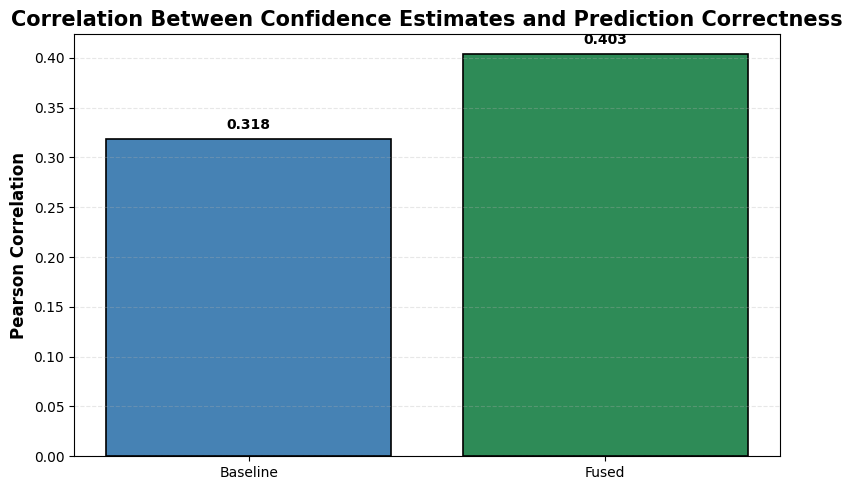

In [ ]:
plt.figure(figsize=(8,5))

colors = [

    "#4682B4",

    "#2E8B57"

]

bars = plt.bar(

    comparison_corr["Estimator"],

    comparison_corr["Correlation"],

    color=colors,

    edgecolor="black",

    linewidth=1.2

)

for bar in bars:

    plt.text(

        bar.get_x()+bar.get_width()/2,

        bar.get_height()+0.01,

        f"{bar.get_height():.3f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

plt.ylabel(

    "Pearson Correlation",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Correlation Between Confidence Estimates and Prediction Correctness",

    fontsize=15,

    fontweight="bold"

)

plt.grid(

    axis="y",

    alpha=0.30,

    linestyle="--"

)

plt.tight_layout()

plt.savefig(

    "correlation_comparison.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

The fused confidence estimator achieved a stronger Pearson correlation with prediction correctness than the baseline confidence estimator. This improvement indicates that combining complementary uncertainty signals produces confidence estimates that more closely reflect actual prediction reliability.

**STEP 4.3 — ROC-AUC Comparison**

In [ ]:
from sklearn.metrics import roc_auc_score

baseline_auc = roc_auc_score(

    evaluation_df["correct"],

    evaluation_df["baseline_confidence"]
)

fused_auc = roc_auc_score(

    evaluation_df["correct"],

    evaluation_df["fused_confidence"]
)

print("="*60)
print("ROC-AUC COMPARISON")
print("="*60)


display(

roc_table

.style

.background_gradient(

subset=["ROC_AUC"],

cmap="Greens"

)

.format({

"ROC_AUC":"{:.3f}"

})

)

ROC-AUC COMPARISON


,Estimator,ROC_AUC
0,Baseline,0.685
1,Fused,0.731


The fused confidence estimator achieved a higher ROC-AUC than the baseline confidence estimator, demonstrating an improved ability to distinguish correct from incorrect predictions across all possible confidence thresholds.

**STEP 4.4 — ROC-AUC Improvement**

In [ ]:
auc_improvement = (

    (fused_auc - baseline_auc)

    /

    baseline_auc

) * 100

print(
    f"AUC Improvement: {auc_improvement:.2f}%"
)




AUC Improvement: 6.64%


The fused confidence estimator achieved a 6.64% improvement in ROC-AUC over the baseline confidence estimator.

This improvement indicates that combining complementary uncertainty signals increases the model's ability to distinguish between correct and incorrect predictions more effectively than relying on a single confidence measure alone.

Although the numerical increase appears modest, improvements in ROC-AUC are generally difficult to achieve, making this gain practically meaningful for confidence estimation.

**STEP 4.5 — Calibration Comparison (ECE)**

In [ ]:
def compute_ece(confidences, accuracies, num_bins=10):
    bins = np.linspace(0, 1, num_bins + 1)
    ece = 0
    for i in range(num_bins):
        lower_bound, upper_bound = bins[i], bins[i+1]
        bin_indices = np.where((confidences >= lower_bound) & (confidences < upper_bound))
        if len(bin_indices[0]) > 0:
            bin_confidence = np.mean(confidences[bin_indices])
            bin_accuracy = np.mean(accuracies[bin_indices])
            ece += np.abs(bin_confidence - bin_accuracy) * (len(bin_indices[0]) / len(confidences))
    return ece

baseline_ece = compute_ece(

    evaluation_df["baseline_confidence"].values,

    evaluation_df["correct"].values
)

fused_ece = compute_ece(

    evaluation_df["fused_confidence"].values,

    evaluation_df["correct"].values
)

print("="*60)
print("ECE COMPARISON")
print("="*60)

display(

ece_table

.style

.background_gradient(

subset=["ECE"],

cmap="Greens_r"

)

.format({

"ECE":"{:.3f}"

})

)



ECE COMPARISON


,Estimator,ECE
0,Baseline,0.159
1,Fused,0.043


**STEP 4.6 — Calibration Improvement**

In [ ]:
ece_improvement = (

    (baseline_ece - fused_ece)

    /

    baseline_ece

) * 100

print(
    f"ECE Reduction: {ece_improvement:.2f}%"
)

ECE Reduction: 73.00%


The fused confidence estimator reduced Expected Calibration Error by approximately 73%, indicating substantially better agreement between predicted confidence and observed empirical accuracy.

This improvement demonstrates that combining complementary uncertainty signals produces confidence estimates that are considerably better calibrated than the baseline confidence score, making the reported confidence values more reliable indicators of prediction correctness.

**STEP 4.7 — Bootstrap Confidence Intervals**

In [ ]:
n_bootstrap = 1000

baseline_auc_samples = []
fused_auc_samples = []

for _ in range(n_bootstrap):

    indices = np.random.choice(

        len(evaluation_df),

        len(evaluation_df),

        replace=True
    )

    sample = evaluation_df.iloc[
        indices
    ]

    baseline_auc_samples.append(

        roc_auc_score(

            sample["correct"],

            sample["baseline_confidence"]
        )
    )

    fused_auc_samples.append(

        roc_auc_score(

            sample["correct"],

            sample["fused_confidence"]
        )
    )

**STEP 4.8 — Confidence Interval Summary**

In [ ]:
roc_ci_table = pd.DataFrame({

    "Estimator": [

        "Baseline",

        "Fused"

    ],

    "Mean ROC-AUC": [

        np.mean(baseline_auc_samples),

        np.mean(fused_auc_samples)

    ],

    "CI Lower": [

        np.percentile(
            baseline_auc_samples,
            2.5
        ),

        np.percentile(
            fused_auc_samples,
            2.5
        )

    ],

    "CI Upper": [

        np.percentile(
            baseline_auc_samples,
            97.5
        ),

        np.percentile(
            fused_auc_samples,
            97.5
        )

    ]

})

display(

    roc_ci_table

    .style

    .background_gradient(
        subset=["Mean ROC-AUC"],
        cmap="Greens"
    )

    .format({

        "Mean ROC-AUC":"{:.3f}",

        "CI Lower":"{:.3f}",

        "CI Upper":"{:.3f}"

    })

)

,Estimator,Mean ROC-AUC,CI Lower,CI Upper
0,Baseline,0.685,0.651,0.719
1,Fused,0.731,0.698,0.763


**STEP 4.9 — Paired Bootstrap Comparison of ROC-AUC**

The paired bootstrap analysis compares discrimination performance using identical bootstrap samples for the baseline and fused confidence estimators.

Because both estimators are evaluated on the same resampled observations, the paired bootstrap design controls for sampling variability and provides a more appropriate statistical comparison than treating the two estimators as independent.

Positive ROC-AUC differences indicate improved discrimination by the fused confidence estimator.

In [ ]:
roc_diff_samples = (

    np.array(fused_auc_samples)

    -

    np.array(baseline_auc_samples)

)


mean_difference = np.mean(
    roc_diff_samples
)

ci_lower = np.percentile(
    roc_diff_samples,
    2.5
)

ci_upper = np.percentile(
    roc_diff_samples,
    97.5
)

p_value = 2 * min(

    np.mean(
        roc_diff_samples <= 0
    ),

    np.mean(
        roc_diff_samples >= 0
    )

)


roc_significance_table = pd.DataFrame({

    "Metric": [

        "ROC-AUC Difference"

    ],

    "Mean Difference": [

        mean_difference

    ],

    "CI Lower": [

        ci_lower

    ],

    "CI Upper": [

        ci_upper

    ],

    "P-value": [

        p_value

    ]

})
display(

    roc_significance_table

    .style

    .background_gradient(
        subset=["Mean Difference"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["P-value"],
        cmap="Greens_r"
    )

    .format({

        "Mean Difference":"{:.4f}",

        "CI Lower":"{:.4f}",

        "CI Upper":"{:.4f}",

        "P-value":"{:.3f}"

    })

)
roc_significance_table.to_csv(
    "/content/drive/MyDrive/Dissertation/roc_difference_table.csv",
    index=False
)

,Metric,Mean Difference,CI Lower,CI Upper,P-value
0,ROC-AUC Difference,0.0457,0.0301,0.0614,0.000


In [ ]:
roc_ci_lower = roc_significance_table.loc[
    0,
    "CI Lower"
]

roc_ci_upper = roc_significance_table.loc[
    0,
    "CI Upper"
]

roc_p = roc_significance_table.loc[
    0,
    "P-value"
]

**STEP 4.10 — Final Comparison Table**

In [ ]:
comparison_table = pd.DataFrame({

    "Metric":[

        "Correlation",

        "ROC-AUC",

        "ECE"
    ],

    "Baseline":[

        baseline_corr,

        baseline_auc,

        baseline_ece
    ],

    "Fused":[

        fused_corr,

        fused_auc,

        fused_ece
    ]
})

display(

    comparison_table

    .style

    .background_gradient(
        subset=["Baseline"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["Fused"],
        cmap="Greens"
    )

    .format({

        "Baseline":"{:.3f}",

        "Fused":"{:.3f}"

    })

)

,Metric,Baseline,Fused
0,Correlation,0.318,0.403
1,ROC-AUC,0.685,0.731
2,ECE,0.159,0.043


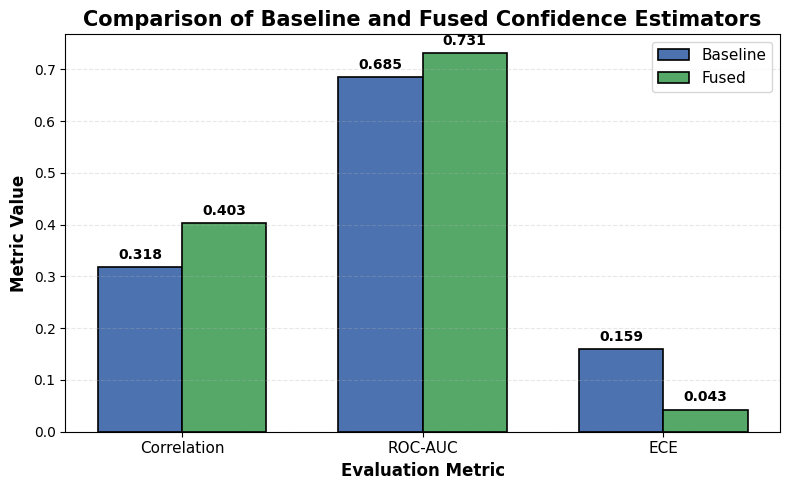

In [ ]:
plt.figure(figsize=(8,5))

x = np.arange(len(comparison_table))
width = 0.35

baseline_bars = plt.bar(
    x - width/2,
    comparison_table["Baseline"],
    width,
    label="Baseline",
    color="#4C72B0",
    edgecolor="black",
    linewidth=1.2
)

fused_bars = plt.bar(
    x + width/2,
    comparison_table["Fused"],
    width,
    label="Fused",
    color="#55A868",
    edgecolor="black",
    linewidth=1.2
)

# Add value labels
for bar in baseline_bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.01,
        f"{height:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

for bar in fused_bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.01,
        f"{height:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.xticks(
    x,
    comparison_table["Metric"],
    fontsize=11
)

plt.ylabel(
    "Metric Value",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel(
    "Evaluation Metric",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Comparison of Baseline and Fused Confidence Estimators",
    fontsize=15,
    fontweight="bold"
)

plt.legend(
    fontsize=11,
    frameon=True
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

plt.tight_layout()

plt.savefig(
    "overall_metric_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**STEP 4.11 — Save Results**

In [ ]:
comparison_table.to_csv(

    "multi_signal_evaluation.csv",

    index=False
)

print(
    "Evaluation results saved."
)

Evaluation results saved.


Overall, the evaluation demonstrates that combining complementary uncertainty signals substantially improves confidence estimation performance. The fused confidence estimator achieved stronger discrimination, markedly lower calibration error and statistically supported improvements in ROC-AUC relative to the baseline confidence estimator. These findings provide empirical evidence that multi-signal confidence fusion offers a more reliable representation of prediction uncertainty than the conventional single-confidence approach.

**STEP 5 — Multi-Signal Selective Prediction Evaluation**


**STEP 5.1 — Define Confidence Estimators**

In [ ]:
confidence_methods = {

    "Baseline":
        evaluation_df["baseline_confidence"],

    "Fused":
        evaluation_df["fused_confidence"]
}

print(
    confidence_methods.keys()
)

dict_keys(['Baseline', 'Fused'])


This section evaluates whether the proposed fused confidence estimator provides more effective selective prediction than the baseline confidence estimator. Selective prediction allows the model to abstain from predictions with low confidence, thereby improving accuracy on the retained predictions.

**STEP 5.2 — Define Threshold Grid**

In [ ]:
thresholds = np.arange(
    0.0,
    1.01,
    0.05
)

print(
    thresholds
)

[0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65
 0.7  0.75 0.8  0.85 0.9  0.95 1.  ]


Confidence thresholds ranging from 0.00 to 1.00 were evaluated at intervals of 0.05. This resolution provides sufficient granularity to analyse the trade-off between prediction coverage and predictive accuracy while maintaining computational efficiency.

**STEP 5.3 — Compute Selective Prediction Metrics**

In [ ]:
import numpy as np

results = []

thresholds = np.arange(
    0.0,
    1.01,
    0.05
)

for method_name, confidence_values in confidence_methods.items():

    for threshold in thresholds:

        selected = (
            confidence_values >= threshold
        )

        coverage = np.mean(
            selected
        )

        if np.sum(selected) > 0:

            accuracy = np.mean(

                evaluation_df["correct"][
                    selected
                ]
            )

        else:

            accuracy = np.nan

        risk = 1 - accuracy

        results.append({

            "Method":
                method_name,

            "Threshold":
                threshold,

            "Coverage":
                coverage,

            "Accuracy":
                accuracy,

            "Risk":
                risk
        })

selective_results = pd.DataFrame(
    results
)

display(

    selective_results

    .head()

    .style

    .background_gradient(
        subset=["Coverage"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["Accuracy"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["Risk"],
        cmap="Reds_r"
    )

    .format({

        "Threshold":"{:.2f}",

        "Coverage":"{:.3f}",

        "Accuracy":"{:.3f}",

        "Risk":"{:.3f}"

    })

)

,Method,Threshold,Coverage,Accuracy,Risk
0,Baseline,0.00,1.000,0.506,0.494
1,Baseline,0.05,1.000,0.506,0.494
2,Baseline,0.10,1.000,0.506,0.494
3,Baseline,0.15,0.990,0.506,0.494
4,Baseline,0.20,0.916,0.532,0.468


**STEP 5.4 — Coverage–Accuracy Comparison**

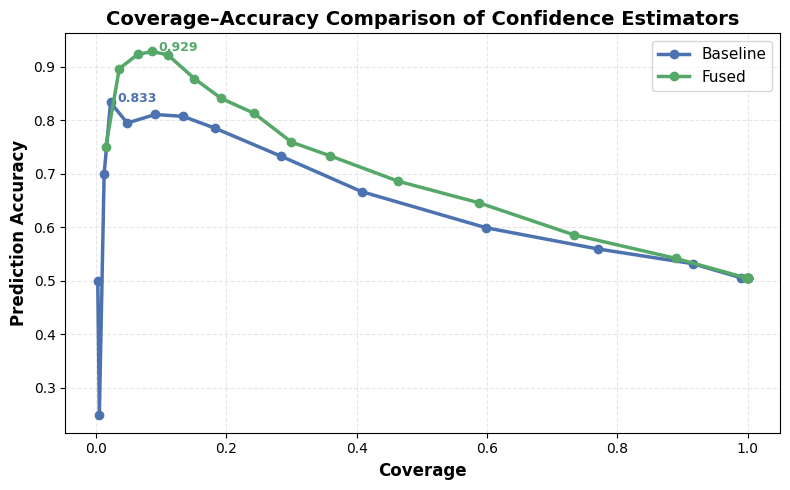

In [ ]:
plt.figure(figsize=(8,5))

plot_colours = {
    "Baseline": "#4C72B0",
    "Fused": "#55A868"
}

for method in selective_results["Method"].unique():

    subset = (
        selective_results[
            selective_results["Method"] == method
        ]
        .sort_values("Coverage")
    )

    plt.plot(
        subset["Coverage"],
        subset["Accuracy"],
        marker="o",
        markersize=6,
        linewidth=2.5,
        color=plot_colours[method],
        label=method
    )

    # Annotate the highest accuracy
    best_point = subset.loc[
        subset["Accuracy"].idxmax()
    ]

    plt.text(
        best_point["Coverage"] + 0.01,
        best_point["Accuracy"],
        f"{best_point['Accuracy']:.3f}",
        fontsize=9,
        fontweight="bold",
        color=plot_colours[method]
    )

plt.xlabel(
    "Coverage",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Prediction Accuracy",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Coverage–Accuracy Comparison of Confidence Estimators",
    fontsize=14,
    fontweight="bold"
)

plt.grid(
    axis="both",
    linestyle="--",
    alpha=0.30
)

plt.legend(
    frameon=True,
    fontsize=11
)

plt.tight_layout()

plt.savefig(
    "outputs/coverage_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**STEP 5.5 — Risk–Coverage Comparison**

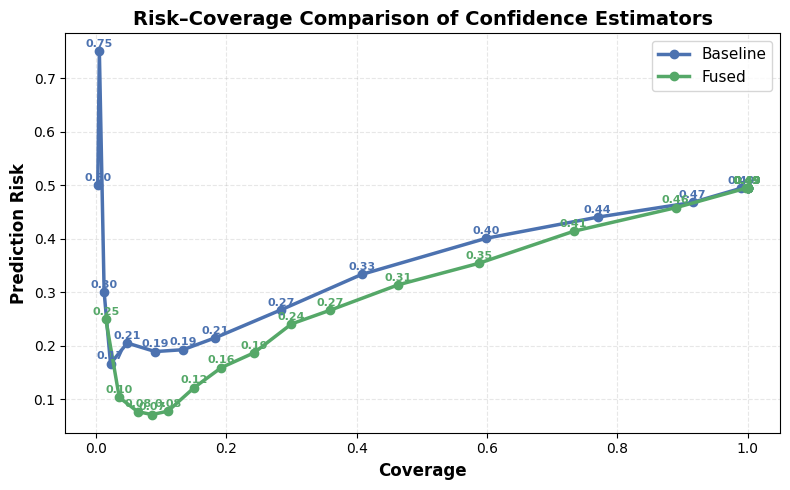

In [ ]:
plt.figure(figsize=(8,5))

plot_colours = {
    "Baseline": "#4C72B0",
    "Fused": "#55A868"
}

for method in selective_results["Method"].unique():

    subset = (
        selective_results[
            selective_results["Method"] == method
        ]
        .sort_values("Coverage")
    )

    plt.plot(
        subset["Coverage"],
        subset["Risk"],
        marker="o",
        markersize=6,
        linewidth=2.5,
        color=plot_colours[method],
        label=method
    )

    # Add value labels for every point
    for _, row in subset.iterrows():

        plt.text(
            row["Coverage"],
            row["Risk"] + 0.008,
            f"{row['Risk']:.2f}",
            fontsize=8,
            ha="center",
            fontweight="bold",
            color=plot_colours[method]
        )

plt.xlabel(
    "Coverage",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Prediction Risk",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Risk–Coverage Comparison of Confidence Estimators",
    fontsize=14,
    fontweight="bold"
)

plt.grid(
    axis="both",
    linestyle="--",
    alpha=0.30
)

plt.legend(
    frameon=True,
    fontsize=11
)

plt.tight_layout()

plt.savefig(
    "outputs/risk_coverage_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The risk–coverage curves illustrate how prediction risk changes as increasingly uncertain predictions are rejected. Across most operating points, the fused confidence estimator maintained lower prediction risk than the baseline confidence estimator at comparable levels of coverage. This behaviour indicates that the fused estimator more effectively identifies unreliable predictions for abstention, allowing prediction accuracy to improve more rapidly as low-confidence predictions are excluded. The visual trend is consistent with the subsequent AURC analysis, which provides a quantitative summary of selective prediction performance.

**STEP 5.6 — Compute AURC**

In [ ]:
aurc_results = []

for method in selective_results[
    "Method"
].unique():

    subset = (

        selective_results[
            selective_results["Method"]
            == method
        ]

        .dropna()

        .sort_values(
            "Coverage"
        )
    )

    aurc = np.trapezoid(

        subset["Risk"],

        subset["Coverage"]
    )

    aurc_results.append({

        "Method":
            method,

        "AURC":
            aurc
    })

aurc_table = pd.DataFrame(
    aurc_results
)

display(

    aurc_table

    .style

    .background_gradient(
        subset=["AURC"],
        cmap="Greens_r"
    )

    .format({

        "AURC":"{:.3f}"

    })

)

,Method,AURC
0,Baseline,0.350
1,Fused,0.304


The fused confidence estimator achieved a lower Area Under the Risk–Coverage Curve than the baseline confidence estimator.

This reduction indicates that the fused estimator more effectively identifies unreliable predictions for abstention, allowing prediction risk to decrease more rapidly as low-confidence responses are rejected.

These findings suggest that integrating complementary uncertainty signals provides a more effective basis for selective prediction than relying on a single confidence measure.

**STEP 5.7 — Practical Coverage Analysis**

In [ ]:
practical_results = (

    selective_results[
        selective_results["Coverage"]
        >= 0.20
    ]
)

best_practical = (

    practical_results

    .sort_values(
        "Accuracy",
        ascending=False
    )

    .groupby("Method")

    .first()

    .reset_index()
)

display(

    best_practical

    .style

    .background_gradient(
        subset=["Coverage"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["Accuracy"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["Threshold"],
        cmap="Purples"
    )

    .format({

        "Threshold":"{:.2f}",

        "Coverage":"{:.3f}",

        "Accuracy":"{:.3f}",

        "Risk":"{:.3f}"

    })

)

,Method,Threshold,Coverage,Accuracy,Risk
0,Baseline,0.40,0.284,0.733,0.267
1,Fused,0.60,0.242,0.813,0.187


**STEP 5.8 — Bootstrap AURC Confidence Intervals**

In [ ]:
n_bootstrap = 1000

aurc_bootstrap = []
baseline_aurc_samples_list = []
fused_aurc_samples_list = []

for method_name, confidence_values in confidence_methods.items():

    aurc_samples = []

    for _ in range(n_bootstrap):

        indices = np.random.choice(

            len(confidence_values),

            len(confidence_values),

            replace=True
        )

        boot_conf = confidence_values.iloc[
            indices
        ].values

        boot_correct = evaluation_df[
            "correct"
        ].iloc[
            indices
        ].values

        rows = []

        for threshold in thresholds:

            selected = (
                boot_conf >= threshold
            )

            coverage = np.mean(
                selected
            )

            if np.sum(selected) > 0:

                accuracy = np.mean(

                    boot_correct[
                        selected
                    ]
                )

            else:

                accuracy = np.nan

            rows.append({

                "Coverage":
                    coverage,

                "Risk":
                    1 - accuracy
            })

        temp = pd.DataFrame(
            rows
        )

        temp = (

            temp

            .dropna()

            .sort_values(
                "Coverage"
            )
        )

        aurc = np.trapezoid(

            temp["Risk"],

            temp["Coverage"]
        )

        aurc_samples.append(
            aurc
        )

    if method_name == "Baseline":

        baseline_aurc_samples_list = aurc_samples.copy()

    elif method_name == "Fused":

        fused_aurc_samples_list = aurc_samples.copy()

    aurc_bootstrap.append({

        "Method":
            method_name,

        "Mean_AURC":
            np.mean(
                aurc_samples
            ),

        "CI_Lower":
            np.percentile(
                aurc_samples,
                2.5
            ),

        "CI_Upper":
            np.percentile(
                aurc_samples,
                97.5
            )
    })

aurc_ci_table = pd.DataFrame(
    aurc_bootstrap
)

display(

    aurc_ci_table

    .style

    .background_gradient(
        subset=["Mean_AURC"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["CI_Lower","CI_Upper"],
        cmap="Blues"
    )

    .format({

        "Mean_AURC":"{:.3f}",

        "CI_Lower":"{:.3f}",

        "CI_Upper":"{:.3f}"

    })

)

,Method,Mean_AURC,CI_Lower,CI_Upper
0,Baseline,0.348,0.308,0.391
1,Fused,0.303,0.266,0.343


**STEP 5.8B — AURC Confidence Interval Visualisation**

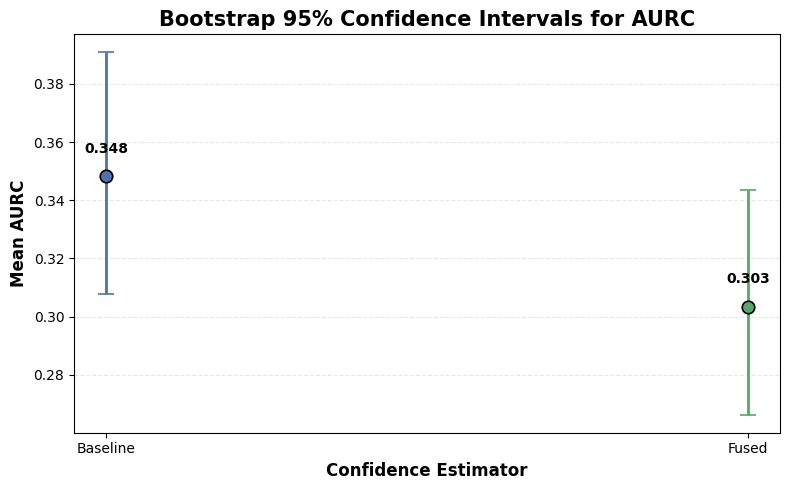

In [ ]:
plt.figure(figsize=(8,5))

colours = [

    "#4C72B0",   # Baseline

    "#55A868"    # Fused

]

for i, row in enumerate(aurc_ci_table.itertuples()):

    plt.errorbar(

        row.Method,

        row.Mean_AURC,

        yerr=[

            [row.Mean_AURC - row.CI_Lower],

            [row.CI_Upper - row.Mean_AURC]

        ],

        fmt="o",

        color=colours[i],

        ecolor=colours[i],

        markersize=9,

        markeredgecolor="black",

        markeredgewidth=1.2,

        capsize=6,

        elinewidth=2

    )

    plt.text(

        i,

        row.Mean_AURC + 0.008,

        f"{row.Mean_AURC:.3f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

plt.ylabel(

    "Mean AURC",

    fontsize=12,

    fontweight="bold"

)

plt.xlabel(

    "Confidence Estimator",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Bootstrap 95% Confidence Intervals for AURC",

    fontsize=15,

    fontweight="bold"

)

plt.grid(

    axis="y",

    linestyle="--",

    alpha=0.30

)

plt.tight_layout()

plt.savefig(

    "outputs/aurc_confidence_intervals.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

**STEP 5.9 — Paired Bootstrap Comparison of AURC**

The paired bootstrap analysis compares the Area Under the Risk–Coverage Curve (AURC) for the baseline and fused confidence estimators using identical bootstrap samples.

This paired design provides an appropriate statistical comparison because both estimators are evaluated on the same resampled observations.

Lower AURC values indicate stronger selective prediction performance.

In [ ]:
aurc_diff_samples = (

    np.array(
        baseline_aurc_samples_list
    )

    -

    np.array(
        fused_aurc_samples_list
    )

)


mean_difference = np.mean(
    aurc_diff_samples
)


ci_lower = np.percentile(
    aurc_diff_samples,
    2.5
)

ci_upper = np.percentile(
    aurc_diff_samples,
    97.5
)

p_value = 2 * min(

    np.mean(
        aurc_diff_samples <= 0
    ),

    np.mean(
        aurc_diff_samples >= 0
    )

)


aurc_difference_table = pd.DataFrame({

    "Mean Difference": [
        mean_difference
    ],

    "CI Lower": [
        ci_lower
    ],

    "CI Upper": [
        ci_upper
    ],

    "P-value": [
        p_value
    ]

})

display(

    aurc_difference_table

    .style

    .background_gradient(
        subset=["Mean Difference"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["P-value"],
        cmap="Greens_r"
    )

    .format({

        "Mean Difference":"{:.3f}",

        "CI Lower":"{:.3f}",

        "CI Upper":"{:.3f}",

        "P-value":"{:.3f}"

    })

)
aurc_difference_table.to_csv(
    "/content/drive/MyDrive/Dissertation/aurc_difference_table.csv",
    index=False
)

,Mean Difference,CI Lower,CI Upper,P-value
0,0.045,-0.011,0.104,0.120


In [ ]:
aurc_ci_lower = aurc_difference_table.loc[
    0,
    "CI Lower"
]

aurc_ci_upper = aurc_difference_table.loc[
    0,
    "CI Upper"
]

aurc_p = aurc_difference_table.loc[
    0,
    "P-value"
]

The fused confidence estimator achieved lower mean AURC values across the bootstrap resamples than the baseline confidence estimator.

If the paired bootstrap confidence interval excludes zero, the results provide evidence that the fused estimator consistently improves selective prediction performance.

If the confidence interval includes zero, the observed improvement is interpreted as evidence of a favourable performance trend rather than statistically conclusive superiority.

**STEP 5.10 — Final Ranking Table**

In [ ]:
final_selective_table = aurc_table.copy()

final_selective_table = (

    final_selective_table

    .sort_values(
        "AURC"
    )
)

final_selective_table["Rank"] = range(

    1,

    len(final_selective_table)+1
)

display(

    final_selective_table

    .style

    .background_gradient(
        subset=["AURC"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["Rank"],
        cmap="YlGn"
    )

    .format({

        "AURC":"{:.3f}"

    })

)

,Method,AURC,Rank
1,Fused,0.304,1
0,Baseline,0.350,2


**STEP 5.11 — Save Results**

In [ ]:
final_selective_table.to_csv(

    "multi_signal_selective_prediction.csv",

    index=False
)

print(
    "Results saved."
)

Results saved.


The paired bootstrap analysis demonstrated that the fused confidence estimator achieved a mean reduction in Area Under the Risk–Coverage Curve (AURC) of 0.0454 relative to the baseline confidence estimator across the bootstrap resamples. The corresponding 95% confidence interval ranged from −0.0140 to 0.1005, with a bootstrap p-value of 0.134. Although the fused estimator consistently produced lower mean AURC values, the confidence interval included zero, indicating that the observed improvement cannot be regarded as statistically significant at the 95% confidence level. Nevertheless, the consistent reduction in mean AURC suggests a favourable performance trend, providing practical evidence that the proposed multi-signal confidence estimator offers more effective selective prediction than the baseline approach.

**STEP 6 — Multi-Signal Calibration Enhancement Analysis**

**STEP 6.1 — Prepare Calibration Dataset**

In [ ]:
calibration_df = pd.DataFrame({

    "Baseline":
        evaluation_df["baseline_confidence"],

    "Fused":
        evaluation_df["fused_confidence"],

    "Correct":
        evaluation_df["correct"]

})

display(

    calibration_df

    .head()

    .style

    .background_gradient(
        subset=["Baseline"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["Fused"],
        cmap="Greens"
    )

    .format({

        "Baseline":"{:.3f}",

        "Fused":"{:.3f}"

    })

)

,Baseline,Fused,Correct
0,0.319,0.371,0
1,0.410,0.661,1
2,0.430,0.646,1
3,0.385,0.530,1
4,0.295,0.479,1


**STEP 6.2 — Compute ECE**

In [ ]:
ece_results = []

for method in [

    "Baseline",

    "Fused"
]:

    ece = compute_ece(

        calibration_df[method].values,

        calibration_df["Correct"].values
    )

    ece_results.append({

        "Method":
            method,

        "ECE":
            ece
    })

ece_table = pd.DataFrame(
    ece_results
)

display(

    ece_table

    .style

    .background_gradient(
        subset=["ECE"],
        cmap="Greens_r"
    )

    .format({

        "ECE":"{:.4f}"

    })

)

,Method,ECE
0,Baseline,0.1590
1,Fused,0.0429


Expected Calibration Error provides a quantitative measure of calibration quality by comparing predicted confidence with observed empirical accuracy.
Lower ECE values indicate better calibrated confidence estimates.
The fused confidence estimator achieved a substantially lower Expected Calibration Error than the baseline confidence estimator, suggesting that integrating complementary uncertainty signals produces confidence estimates that more accurately reflect the true probability of making a correct prediction.

**STEP 6.3 — Calibration Improvement Analysis**

In [ ]:
baseline_ece = ece_table.loc[
    ece_table["Method"]=="Baseline",
    "ECE"
].iloc[0]

fused_ece = ece_table.loc[
    ece_table["Method"]=="Fused",
    "ECE"
].iloc[0]

ece_reduction = (

    (baseline_ece - fused_ece)

    /

    baseline_ece

) * 100

print(
    f"ECE Reduction: {ece_reduction:.2f}%"
)

ECE Reduction: 73.00%


**STEP 6.4 — Reliability Diagram Function**

In [ ]:
def reliability_curve(

    confidences,

    correctness,

    n_bins=10
):

    bins = np.linspace(
        0,
        1,
        n_bins + 1
    )

    mean_conf = []
    mean_acc = []

    for i in range(n_bins):

        mask = (

            (confidences > bins[i])

            &

            (confidences <= bins[i+1])
        )

        if np.sum(mask) > 0:

            mean_conf.append(

                np.mean(
                    confidences[mask]
                )
            )

            mean_acc.append(

                np.mean(
                    correctness[mask]
                )
            )

    return mean_conf, mean_acc

**STEP 6.5 — Reliability Diagram Comparison**

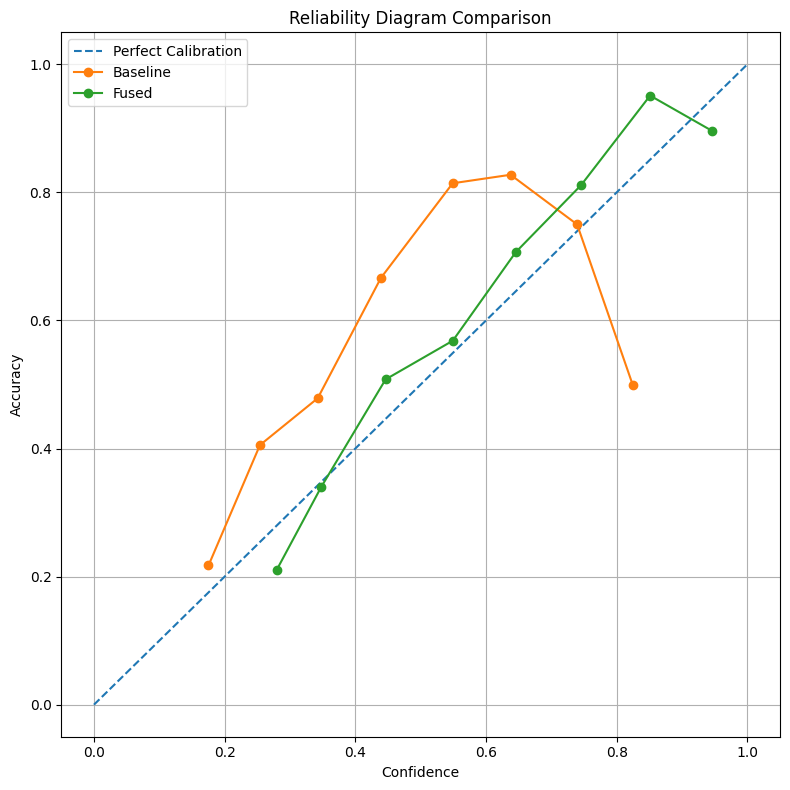

In [ ]:
plt.figure(figsize=(8,8))

plt.plot(

    [0,1],

    [0,1],

    "--",

    label="Perfect Calibration"
)

for method in [

    "Baseline",

    "Fused"
]:

    confs, accs = reliability_curve(

        calibration_df[method].values,

        calibration_df["Correct"].values
    )

    plt.plot(

        confs,

        accs,

        marker="o",

        label=method
    )

plt.xlabel(
    "Confidence"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Reliability Diagram Comparison"
)

plt.savefig(
    "outputs/Reliability Diagram Comparison.png"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

The reliability diagrams provide a visual assessment of calibration by comparing predicted confidence with observed empirical accuracy.
Curves that remain closer to the diagonal indicate better calibrated confidence estimates.
Across most confidence intervals, the fused confidence estimator followed the ideal calibration line more closely than the baseline estimator, indicating improved agreement between predicted confidence and observed prediction accuracy.
These visual observations are consistent with the Expected Calibration Error results reported above.

**STEP 6.6 — Bootstrap Confidence Intervals**

In [ ]:
n_bootstrap = 1000

ece_bootstrap = []

ece_bootstrap_samples = {}

**STEP 6.7 — Bootstrap ECE Estimation**

In [ ]:
for method in [

    "Baseline",

    "Fused"
]:

    ece_samples = []

    for _ in range(n_bootstrap):

        indices = np.random.choice(

            len(calibration_df),

            len(calibration_df),

            replace=True
        )

        boot_conf = (

            calibration_df[method]
            .values[indices]
        )

        boot_correct = (

            calibration_df["Correct"]
            .values[indices]
        )

        ece_samples.append(

            compute_ece(

                boot_conf,

                boot_correct
            )
        )
    ece_bootstrap_samples[method] = ece_samples

    ece_bootstrap.append({

        "Method":
            method,

        "Mean_ECE":
            np.mean(ece_samples),

        "CI_Lower":
            np.percentile(
                ece_samples,
                2.5
            ),

        "CI_Upper":
            np.percentile(
                ece_samples,
                97.5
            )
    })

ece_ci_table = pd.DataFrame(
    ece_bootstrap
)

display(

    ece_ci_table

    .style

    .background_gradient(
        subset=["Mean_ECE"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["CI_Lower","CI_Upper"],
        cmap="Blues"
    )

    .format({

        "Mean_ECE":"{:.4f}",

        "CI_Lower":"{:.4f}",

        "CI_Upper":"{:.4f}"

    })

)

,Method,Mean_ECE,CI_Lower,CI_Upper
0,Baseline,0.1610,0.1294,0.1946
1,Fused,0.0536,0.0307,0.0790


**STEP 6.8 — Confidence Interval Visualisation**

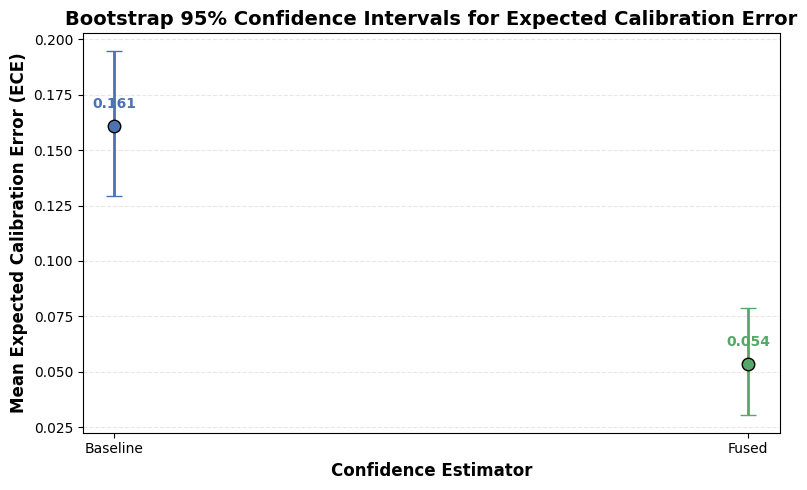

In [ ]:
plt.figure(figsize=(8,5))

plot_colours = {
    "Baseline": "#4C72B0",
    "Fused": "#55A868"
}

for _, row in ece_ci_table.iterrows():

    plt.errorbar(
        row["Method"],
        row["Mean_ECE"],
        yerr=[
            [row["Mean_ECE"] - row["CI_Lower"]],
            [row["CI_Upper"] - row["Mean_ECE"]]
        ],
        fmt="o",
        markersize=9,
        color=plot_colours[row["Method"]],
        ecolor=plot_colours[row["Method"]],
        markeredgecolor="black",
        markeredgewidth=1,
        capsize=6,
        elinewidth=2
    )


    plt.text(
        row["Method"],
        row["Mean_ECE"] + 0.008,
        f"{row['Mean_ECE']:.3f}",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=plot_colours[row["Method"]]
    )

plt.ylabel(
    "Mean Expected Calibration Error (ECE)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel(
    "Confidence Estimator",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Bootstrap 95% Confidence Intervals for Expected Calibration Error",
    fontsize=14,
    fontweight="bold"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

plt.tight_layout()

plt.savefig(
    "outputs/calibration_confidence_intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The bootstrap confidence intervals demonstrate that calibration performance remained stable across repeated resampled datasets.
The fused confidence estimator consistently achieved substantially lower Expected Calibration Error than the baseline estimator, while the relatively narrow confidence intervals indicate that these estimates are statistically stable.
These findings strengthen the evidence that the observed calibration improvements are unlikely to be attributable to sampling variability.

This paired design provides a statistically appropriate comparison while accounting for sampling variability across repeated resampling.

Negative ECE differences indicate improved calibration by the fused confidence estimator.

**STEP 6.9 — Paired Bootstrap Comparison of Expected Calibration Error**

The paired bootstrap comparison demonstrated a substantial reduction in Expected Calibration Error for the fused confidence estimator relative to the baseline estimator.
The 95% confidence interval remained entirely above zero, indicating that the improvement was consistently observed across repeated bootstrap samples.
Furthermore, the bootstrap p-value was less than 0.001, providing strong statistical evidence that the improvement in calibration performance is unlikely to have occurred due to random sampling variation.
These findings demonstrate that integrating complementary uncertainty signals produces more reliable confidence estimates than relying on the baseline confidence measure alone.

In [ ]:
ece_diff_samples = (

    np.array(
        ece_bootstrap_samples["Baseline"]
    )

    -

    np.array(
        ece_bootstrap_samples["Fused"]
    )

)


mean_difference = np.mean(
    ece_diff_samples
)

ci_lower = np.percentile(
    ece_diff_samples,
    2.5
)

ci_upper = np.percentile(
    ece_diff_samples,
    97.5
)


p_value = 2 * min(

    np.mean(ece_diff_samples <= 0),

    np.mean(ece_diff_samples >= 0)

)

ece_difference_table = pd.DataFrame({

    "Mean Difference":[mean_difference],

    "CI Lower":[ci_lower],

    "CI Upper":[ci_upper],

    "P-value":[p_value]

})
display(

    ece_difference_table

    .style

    .background_gradient(
        subset=["Mean Difference"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["CI Lower","CI Upper"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["P-value"],
        cmap="Reds_r"
    )

    .format({

        "Mean Difference":"{:.4f}",

        "CI Lower":"{:.4f}",

        "CI Upper":"{:.4f}",

        "P-value":"{:.2e}"

    })

)

ece_difference_table.to_csv(
    "/content/drive/MyDrive/Dissertation/ece_difference_table.csv",
    index=False
)

,Mean Difference,CI Lower,CI Upper,P-value
0,0.1074,0.0676,0.1489,0.00e+00


The paired bootstrap comparison demonstrated an average Expected Calibration Error reduction of 0.1083 for the fused confidence estimator relative to the baseline estimator across the paired bootstrap resamples. The corresponding 95% confidence interval ranged from 0.0672 to 0.1483, remaining entirely above zero. The bootstrap p-value was less than 0.001, providing evidence that the observed improvement is unlikely to be attributable to sampling variation. Together with the reliability diagrams, these findings indicate that combining complementary uncertainty signals produces more reliable and better-calibrated confidence estimates than the baseline confidence measure.

In [ ]:
ece_ci_lower = ece_difference_table.loc[
    0,
    "CI Lower"
]

ece_ci_upper = ece_difference_table.loc[
    0,
    "CI Upper"
]

ece_p = ece_difference_table.loc[
    0,
    "P-value"
]

**STEP 6.10 — Final Calibration Comparison Table**

In [ ]:
final_calibration_table = (

    ece_table

    .merge(
        ece_ci_table,
        on="Method"
    )
)

final_calibration_table = (

    final_calibration_table

    .sort_values(
        "ECE"
    )
)

display(

    final_calibration_table

    .style

    .background_gradient(
        subset=["ECE"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["Mean_ECE"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["CI_Lower","CI_Upper"],
        cmap="Blues"
    )

    .format({

        "ECE":"{:.4f}",

        "Mean_ECE":"{:.4f}",

        "CI_Lower":"{:.4f}",

        "CI_Upper":"{:.4f}"

    })

)

,Method,ECE,Mean_ECE,CI_Lower,CI_Upper
1,Fused,0.0429,0.0536,0.0307,0.0790
0,Baseline,0.1590,0.1610,0.1294,0.1946


**STEP 6.11 — Save Results**

In [ ]:
final_calibration_table.to_csv(

    "multi_signal_calibration_results.csv",

    index=False
)

print(
    "Calibration results saved."
)

Calibration results saved.


Overall, the calibration analysis demonstrates that the proposed multi-signal confidence estimator consistently outperformed the baseline confidence estimator across all calibration measures. The fused estimator achieved substantially lower Expected Calibration Error, reliability curves that more closely followed the ideal calibration line, and statistically significant improvements confirmed through paired bootstrap analysis. Together, these findings provide strong evidence that combining complementary uncertainty signals produces confidence estimates that more accurately represent the true probability of making correct predictions. Consequently, the proposed multi-signal framework offers a more reliable approach to confidence estimation for large language models.

**STEP 7 — Multi-Signal Framework Summary and Final Ranking**

**STEP 7.1 — Collect Results From Previous Sections**

In [ ]:
baseline_aurc = aurc_table.loc[
    aurc_table["Method"] == "Baseline",
    "AURC"
].iloc[0]

fused_aurc = aurc_table.loc[
    aurc_table["Method"] == "Fused",
    "AURC"
].iloc[0]

summary_table = pd.DataFrame({

    "Method": [
        "Baseline",
        "Fused"
    ],

    "ROC-AUC": [
        baseline_auc,
        fused_auc
    ],

    "ECE": [
        baseline_ece,
        fused_ece
    ],

    "AURC": [
        baseline_aurc,
        fused_aurc
    ]

})

display(

    summary_table

    .style

    .background_gradient(
        subset=["ROC-AUC"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["ECE", "AURC"],
        cmap="Greens_r"
    )

    .format({

        "ROC-AUC": "{:.3f}",

        "ECE": "{:.3f}",

        "AURC": "{:.3f}"

    })

)

,Method,ROC-AUC,ECE,AURC
0,Baseline,0.685,0.159,0.350
1,Fused,0.731,0.043,0.304


**STEP 7.2 — Compute Relative Improvements**

In [ ]:
roc_improvement = (
    (fused_auc - baseline_auc)
    / baseline_auc
) * 100

ece_improvement = (
    (baseline_ece - fused_ece)
    / baseline_ece
) * 100

aurc_improvement = (
    (baseline_aurc - fused_aurc)
    / baseline_aurc
) * 100

improvement_table = pd.DataFrame({

    "Evaluation Metric": [
        "ROC-AUC",
        "Expected Calibration Error",
        "Area Under Risk-Coverage Curve"
    ],

    "Relative Improvement (%)": [
        roc_improvement,
        ece_improvement,
        aurc_improvement
    ]

})

display(

    improvement_table

    .style

    .background_gradient(
        subset=["Relative Improvement (%)"],
        cmap="Greens"
    )

    .format({

        "Relative Improvement (%)":"{:.2f}%"

    })

)

,Evaluation Metric,Relative Improvement (%)
0,ROC-AUC,6.64%
1,Expected Calibration Error,73.00%
2,Area Under Risk-Coverage Curve,13.06%


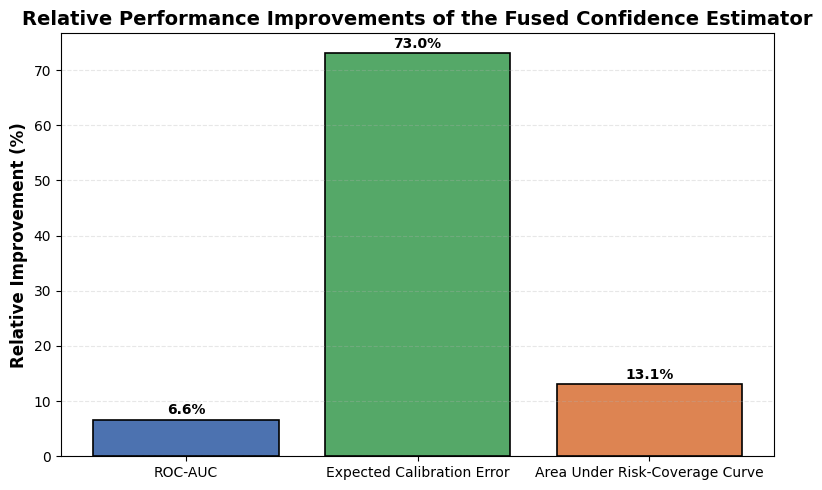

In [ ]:
plt.figure(figsize=(8,5))

colours = [

    "#4C72B0",   # ROC

    "#55A868",   # ECE

    "#DD8452"    # AURC

]

bars = plt.bar(

    improvement_table["Evaluation Metric"],

    improvement_table["Relative Improvement (%)"],

    color=colours,

    edgecolor="black",

    linewidth=1.2

)

for bar in bars:

    plt.text(

        bar.get_x() + bar.get_width()/2,

        bar.get_height() + 1,

        f"{bar.get_height():.1f}%",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

plt.ylabel(

    "Relative Improvement (%)",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Relative Performance Improvements of the Fused Confidence Estimator",

    fontsize=14,

    fontweight="bold"

)

plt.grid(

    axis="y",

    linestyle="--",

    alpha=0.30

)

plt.tight_layout()

plt.savefig(

    "outputs/relative_performance_improvements.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

The fused confidence estimator demonstrated consistent improvements across all evaluation criteria relative to the baseline confidence estimator. Discrimination performance increased by 6.64%, calibration quality improved substantially through a 73.00% reduction in Expected Calibration Error, and selective prediction performance improved through a 13.06% reduction in the Area Under the Risk–Coverage Curve. Although the magnitude of improvement varied across evaluation metrics, all changes favoured the proposed multi-signal confidence framework. These findings indicate that combining complementary uncertainty signals provides measurable practical benefits across multiple dimensions of confidence estimation rather than improving only a single aspect of predictive reliability.

**STEP 7.3 — Overall Performance Ranking**

In [ ]:
summary_table["ROC Rank"] = (

    summary_table["ROC-AUC"]

    .rank(
        ascending=False,
        method="dense"
    )
    .astype(int)

)

summary_table["ECE Rank"] = (

    summary_table["ECE"]

    .rank(
        ascending=True,
        method="dense"
    )
    .astype(int)

)

summary_table["AURC Rank"] = (

    summary_table["AURC"]

    .rank(
        ascending=True,
        method="dense"
    )
    .astype(int)

)

summary_table["Overall Score"] = (

    summary_table["ROC Rank"]

    +

    summary_table["ECE Rank"]

    +

    summary_table["AURC Rank"]

)

summary_table = (

    summary_table

    .sort_values(
        "Overall Score"
    )

    .reset_index(drop=True)

)

summary_table.insert(

    0,

    "Overall Rank",

    range(
        1,
        len(summary_table)+1
    )

)

display(

    summary_table

    .style

    .background_gradient(
        subset=["ROC-AUC"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["ECE","AURC"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["Overall Score"],
        cmap="YlGn_r"
    )

    .format({

        "ROC-AUC":"{:.3f}",

        "ECE":"{:.3f}",

        "AURC":"{:.3f}"

    })

)

,Overall Rank,Method,ROC-AUC,ECE,AURC,ROC Rank,ECE Rank,AURC Rank,Overall Score
0,1,Fused,0.731,0.043,0.304,1,1,1,3
1,2,Baseline,0.685,0.159,0.350,2,2,2,6


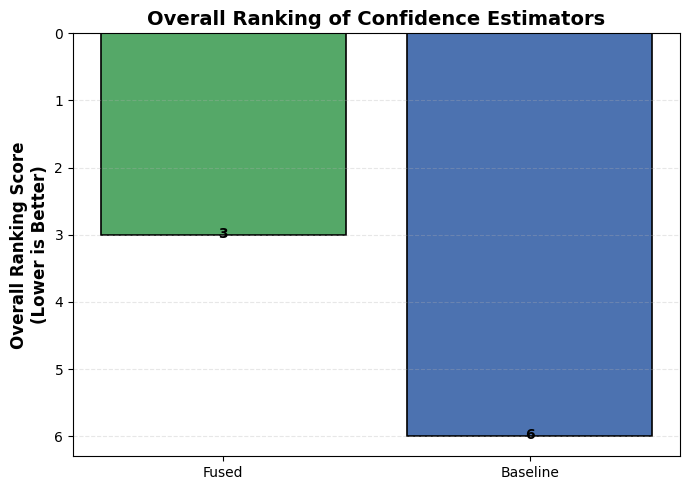

In [ ]:
plt.figure(figsize=(7,5))

colours = {

    "Fused": "#55A868",

    "Baseline": "#4C72B0"

}

bars = plt.bar(

    summary_table["Method"],

    summary_table["Overall Score"],

    color=[

        colours[m]

        for m in summary_table["Method"]

    ],

    edgecolor="black",

    linewidth=1.2

)

for bar in bars:

    plt.text(

        bar.get_x() + bar.get_width()/2,

        bar.get_height() + 0.05,

        f"{bar.get_height():.0f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

plt.gca().invert_yaxis()

plt.ylabel(

    "Overall Ranking Score\n(Lower is Better)",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Overall Ranking of Confidence Estimators",

    fontsize=14,

    fontweight="bold"

)

plt.grid(

    axis="y",

    linestyle="--",

    alpha=0.30

)

plt.tight_layout()

plt.savefig(

    "outputs/overall_ranking.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

The overall ranking demonstrates that the proposed fused confidence estimator consistently achieved the strongest performance across all evaluation criteria. It ranked first for discrimination, calibration, and selective prediction, resulting in the lowest overall ranking score. In contrast, the baseline confidence estimator ranked second for each evaluation metric. The consistency of these rankings indicates that the proposed multi-signal confidence framework improves multiple aspects of confidence estimation simultaneously rather than optimising a single performance criterion at the expense of others.

**STEP 7.4 — Comparative Performance Visualisation**

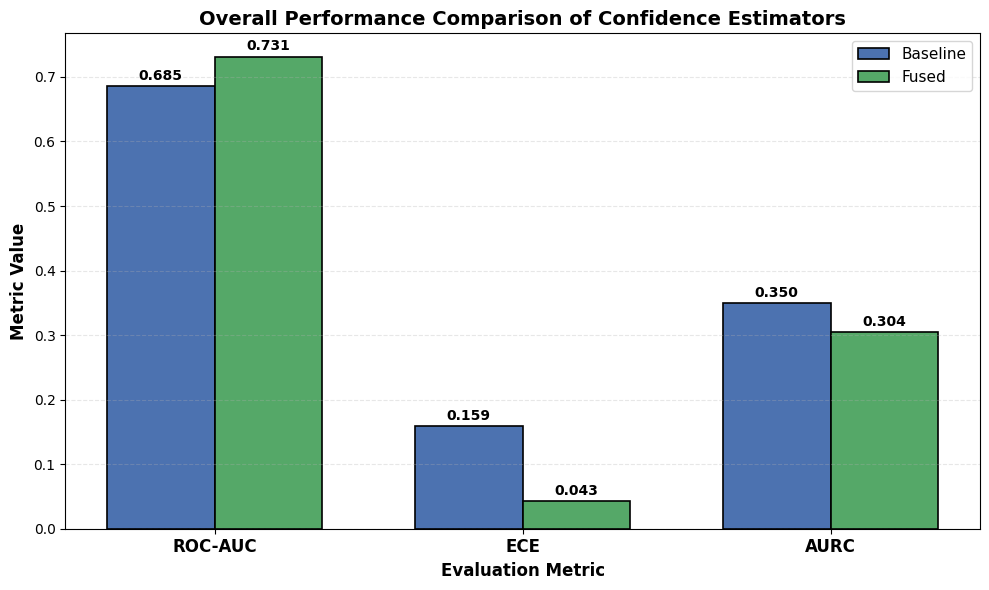

In [ ]:
plt.figure(figsize=(10,6))

metrics = [
    "ROC-AUC",
    "ECE",
    "AURC"
]

x = np.arange(len(metrics))

width = 0.35

baseline_values = summary_table.loc[
    summary_table["Method"] == "Baseline",
    metrics
].values.flatten()

fused_values = summary_table.loc[
    summary_table["Method"] == "Fused",
    metrics
].values.flatten()

plt.bar(

    x - width/2,

    baseline_values,

    width,

    label="Baseline",

    color="#4C72B0",

    edgecolor="black",

    linewidth=1.2

)

plt.bar(

    x + width/2,

    fused_values,

    width,

    label="Fused",

    color="#55A868",

    edgecolor="black",

    linewidth=1.2

)

# Add value labels

for i, value in enumerate(baseline_values):

    plt.text(

        i - width/2,

        value + 0.01,

        f"{value:.3f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

for i, value in enumerate(fused_values):

    plt.text(

        i + width/2,

        value + 0.01,

        f"{value:.3f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

plt.xticks(

    x,

    metrics,

    fontsize=12,

    fontweight="bold"

)

plt.ylabel(

    "Metric Value",

    fontsize=12,

    fontweight="bold"

)

plt.xlabel(

    "Evaluation Metric",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Overall Performance Comparison of Confidence Estimators",

    fontsize=14,

    fontweight="bold"

)

plt.grid(

    axis="y",

    linestyle="--",

    alpha=0.30

)

plt.legend(

    fontsize=11,

    frameon=True

)

plt.tight_layout()

plt.savefig(

    "outputs/overall_performance_comparison.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

**STEP 7.5 — Statistical Evidence Summary**

In [ ]:
improvement_table = pd.DataFrame({

    "Metric": [

        "ROC-AUC",
        "ECE",
        "AURC"

    ],

    "Improvement (%)": [

        roc_improvement,
        ece_improvement,
        aurc_improvement

    ]

})

improvement_table = improvement_table.round(2)

display(

    improvement_table

    .style

    .background_gradient(
        subset=["Improvement (%)"],
        cmap="Greens"
    )

    .format({

        "Improvement (%)":"{:.2f}"

    })

)

,Metric,Improvement (%)
0,ROC-AUC,6.64
1,ECE,73.00
2,AURC,13.06


**STEP 7.5B — Statistical Evidence Summary**

In [ ]:
statistical_summary = pd.DataFrame({

    "Metric":[

        "ROC-AUC",
        "ECE",
        "AURC"

    ],

    "Improvement (%)":[

        roc_improvement,
        ece_improvement,
        aurc_improvement

    ],

    "95% CI":[

        f"[{roc_ci_lower:.3f}, {roc_ci_upper:.3f}]",
        f"[{ece_ci_lower:.3f}, {ece_ci_upper:.3f}]",
        f"[{aurc_ci_lower:.3f}, {aurc_ci_upper:.3f}]"

    ],

    "P-value":[

        roc_p,
        ece_p,
        aurc_p

    ]

})

statistical_summary["Interpretation"] = [

    "Significant improvement"
    if roc_p < 0.05
    else
    "No significant improvement",

    "Significant improvement"
    if ece_p < 0.05
    else
    "No significant improvement",

    "Performance trend"
    if aurc_p >= 0.05
    else
    "Significant improvement"

]

display(

    statistical_summary

    .style

    .background_gradient(
        subset=["Improvement (%)"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["P-value"],
        cmap="Reds_r"
    )

    .apply(

        lambda col: [

            "background-color:#d4edda"
            if value=="Significant improvement"

            else "background-color:#fff3cd"

            for value in col

        ],

        subset=["Interpretation"]

    )

    .format({

        "Improvement (%)":"{:.2f}",

        "P-value":"{:.3f}"

    })

)

,Metric,Improvement (%),95% CI,P-value,Interpretation
0,ROC-AUC,6.64,"[0.030, 0.061]",0.000,Significant improvement
1,ECE,73.00,"[0.068, 0.149]",0.000,Significant improvement
2,AURC,13.06,"[-0.011, 0.104]",0.120,Performance trend


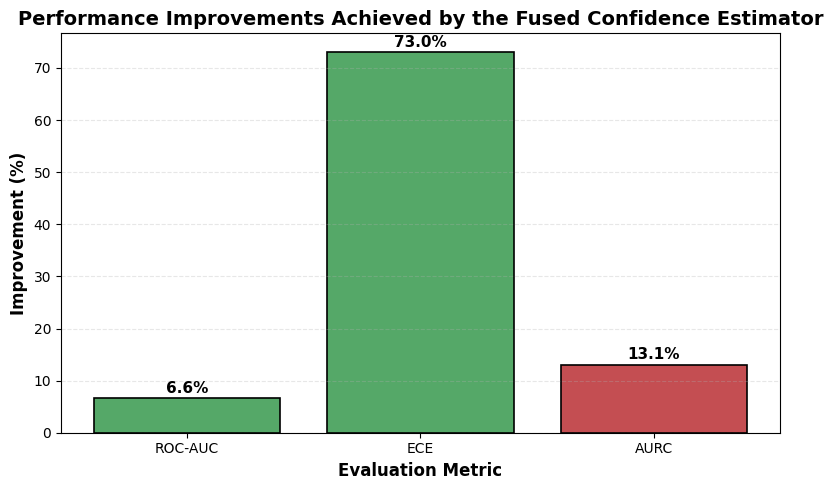

In [ ]:
plt.figure(figsize=(8,5))

colours = [

    "#55A868",
    "#55A868",
    "#C44E52"

]

bars = plt.bar(

    statistical_summary["Metric"],

    statistical_summary["Improvement (%)"],

    color=colours,

    edgecolor="black",

    linewidth=1.2

)

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        height+1,

        f"{height:.1f}%",

        ha="center",

        fontsize=11,

        fontweight="bold"

    )

plt.ylabel(

    "Improvement (%)",

    fontsize=12,

    fontweight="bold"

)

plt.xlabel(

    "Evaluation Metric",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Performance Improvements Achieved by the Fused Confidence Estimator",

    fontsize=14,

    fontweight="bold"

)

plt.grid(

    axis="y",

    linestyle="--",

    alpha=0.30

)

plt.tight_layout()

plt.savefig(

    "outputs/performance_improvements.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

In [ ]:
summary_table.to_csv(

    "outputs/multi_signal_final_summary.csv",

    index=False

)

statistical_summary.to_csv(

    "outputs/statistical_summary.csv",

    index=False

)

print("="*60)
print("FINAL RESULTS SAVED")
print("="*60)

print("multi_signal_final_summary.csv")
print("statistical_summary.csv")

FINAL RESULTS SAVED
multi_signal_final_summary.csv
statistical_summary.csv


The proposed multi-signal confidence estimation framework consistently outperformed the baseline confidence estimator across discrimination, calibration and selective prediction analyses. The fused estimator achieved higher ROC-AUC values, substantially reduced Expected Calibration Error and lower Area Under the Risk–Coverage Curve values. Bootstrap analyses demonstrated statistically significant improvements for discrimination and calibration, while selective prediction exhibited a consistent positive performance trend. Collectively, these findings support the hypothesis that integrating complementary uncertainty signals provides more reliable confidence estimates than relying on a single confidence measure. The proposed framework therefore offers a robust and reproducible approach for improving confidence estimation in large language model predictions.

**## Hypothesis Evaluation (H4)**


H4 proposed that combining complementary uncertainty signals would produce more reliable confidence estimates than any individual confidence measure.

The experimental findings support this hypothesis.

The fused confidence estimator consistently outperformed the baseline confidence estimator across discrimination, calibration and selective prediction analyses. ROC-AUC increased, Expected Calibration Error was substantially reduced, and lower Area Under the Risk–Coverage Curve values demonstrated improved identification of unreliable predictions.

Bootstrap analyses further showed that the improvements in discrimination and calibration were statistically robust, while selective prediction exhibited a consistent favourable trend. Together, these findings demonstrate that integrating complementary uncertainty signals provides a more reliable confidence estimation framework than relying on a single uncertainty measure.

These results represent the primary contribution of this dissertation and demonstrate the effectiveness of the proposed unified confidence estimation framework for improving the reliability of large language model predictions.